<h1 style= 'color: #1f77b4; text-align: center;'>$King County Housing Price Project$</h1>

In [1]:
# Library and Module 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline 
%config InlineBackend.figure_format = 'retina'
import seaborn as sns
import scipy.stats as stats 
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor

>**Sucess Criteria :** 
>    * MAE(Mean Absolute Error) Average absolute prediction error in dollars : Lower is better 
>    * RMSE(Root Mean Squared Error) Error in dollars, giving greater weight to large mistates : Lower is better
>    * R^2 Performace relative to predicting a constant mean : Higher is better, 1 is perfect

# 1. Importing the data

In [2]:
housing_data = pd.read_csv('kc_house_data.csv')
housing_data.head().T

,0,1,2,3,4
id,7129300520,6414100192,5631500400,2487200875,1954400510
date,20141013T000000,20141209T000000,20150225T000000,20141209T000000,20150218T000000
price,221900.0,538000.0,180000.0,604000.0,510000.0
bedrooms,3,3,2,4,3
bathrooms,1.0,2.25,1.0,3.0,2.0
sqft_living,1180,2570,770,1960,1680
sqft_lot,5650,7242,10000,5000,8080
floors,1.0,2.0,1.0,1.0,1.0
waterfront,0,0,0,0,0
view,0,0,0,0,0


In [3]:
housing_data.isna().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [4]:
housing_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [5]:
# Importing data again but this time parse dates, and dropping unwanted columns

unwanted_col = ['id','sqft_living15','sqft_lot15']
housing_data = pd.read_csv('kc_house_data.csv',
                low_memory= False,
                parse_dates=['date'], 
                usecols= lambda column : column not in unwanted_col
                          )

In [6]:
housing_data.head().T

,0,1,2,3,4
date,2014-10-13 00:00:00,2014-12-09 00:00:00,2015-02-25 00:00:00,2014-12-09 00:00:00,2015-02-18 00:00:00
price,221900.0,538000.0,180000.0,604000.0,510000.0
bedrooms,3,3,2,4,3
bathrooms,1.0,2.25,1.0,3.0,2.0
sqft_living,1180,2570,770,1960,1680
sqft_lot,5650,7242,10000,5000,8080
floors,1.0,2.0,1.0,1.0,1.0
waterfront,0,0,0,0,0
view,0,0,0,0,0
condition,3,3,3,5,3


# 3. Reading Data and Finding Patterns

In [7]:
housing_data.describe()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
count,21613,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,2014-10-29 04:38:01.959931,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896
min,2014-05-02 00:00:00,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000
25%,2014-07-22 00:00:00,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000
50%,2014-10-16 00:00:00,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000
75%,2015-02-17 00:00:00,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000
max,2015-05-27 00:00:00,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000
std,NaN,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828


>**Make a copy of the orignal DataFrame**\
> We make a copy of the orignal dataframe so when we manipulate the copy, we've still got our orignal data.

In [8]:
# Make a copy 
df = housing_data.copy()

In [9]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
0,2014-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257
1,2014-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319
2,2015-02-25,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233
3,2014-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393
4,2015-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,2014-05-21,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346
21609,2015-02-23,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362
21610,2014-06-23,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299
21611,2015-01-16,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069


> **Adding datetime parameter for saledate column**

In [10]:
df['sale_year'] = df.date.dt.year
df['age'] = df.sale_year - df.yr_built

In [11]:
df.drop('date', axis = 1, inplace= True)

In [12]:
df.shape

(21613, 19)

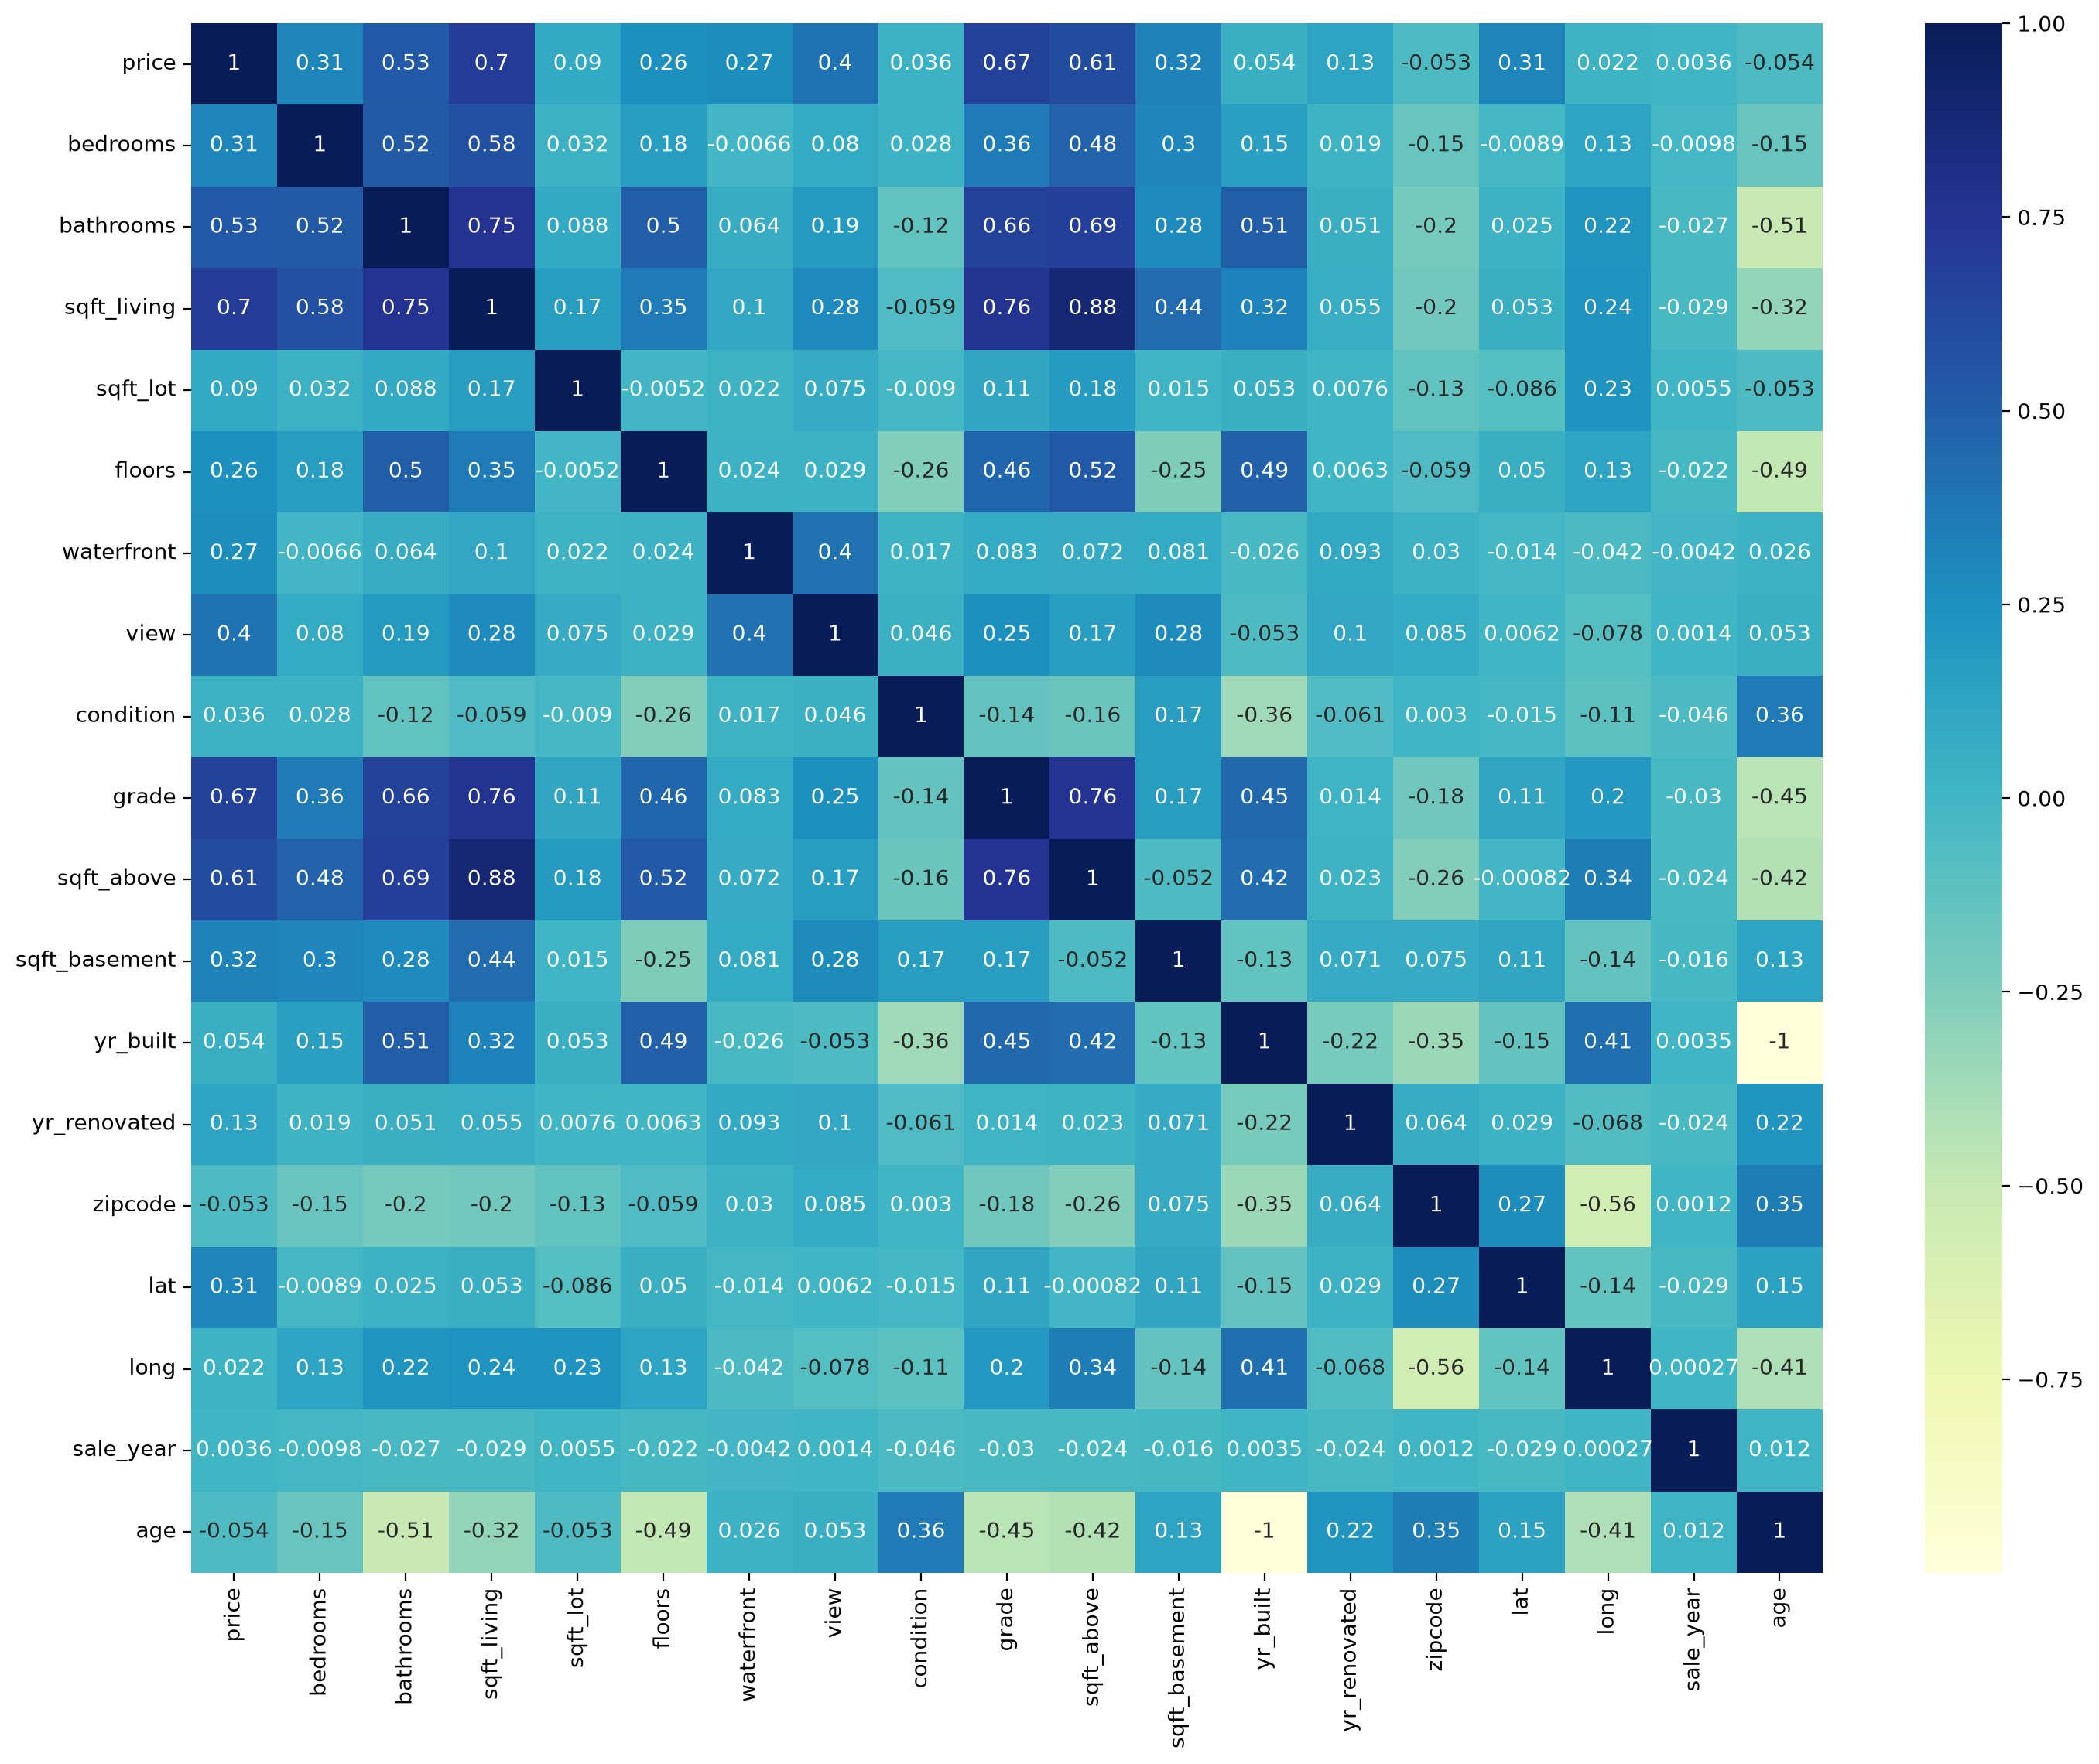

In [13]:
# checking for co-relation between the columns
# method 1 : chart 
df.corr(numeric_only= True)

# method 2 : Graphical representation 
fig, ax = plt.subplots(figsize = (17,13))
ax = sns.heatmap(df.corr(numeric_only = True), annot = True, cmap = 'YlGnBu')

### Univariate Analysis
**Only for those who has good amount of corelation with price value**

>**$PRICE$**

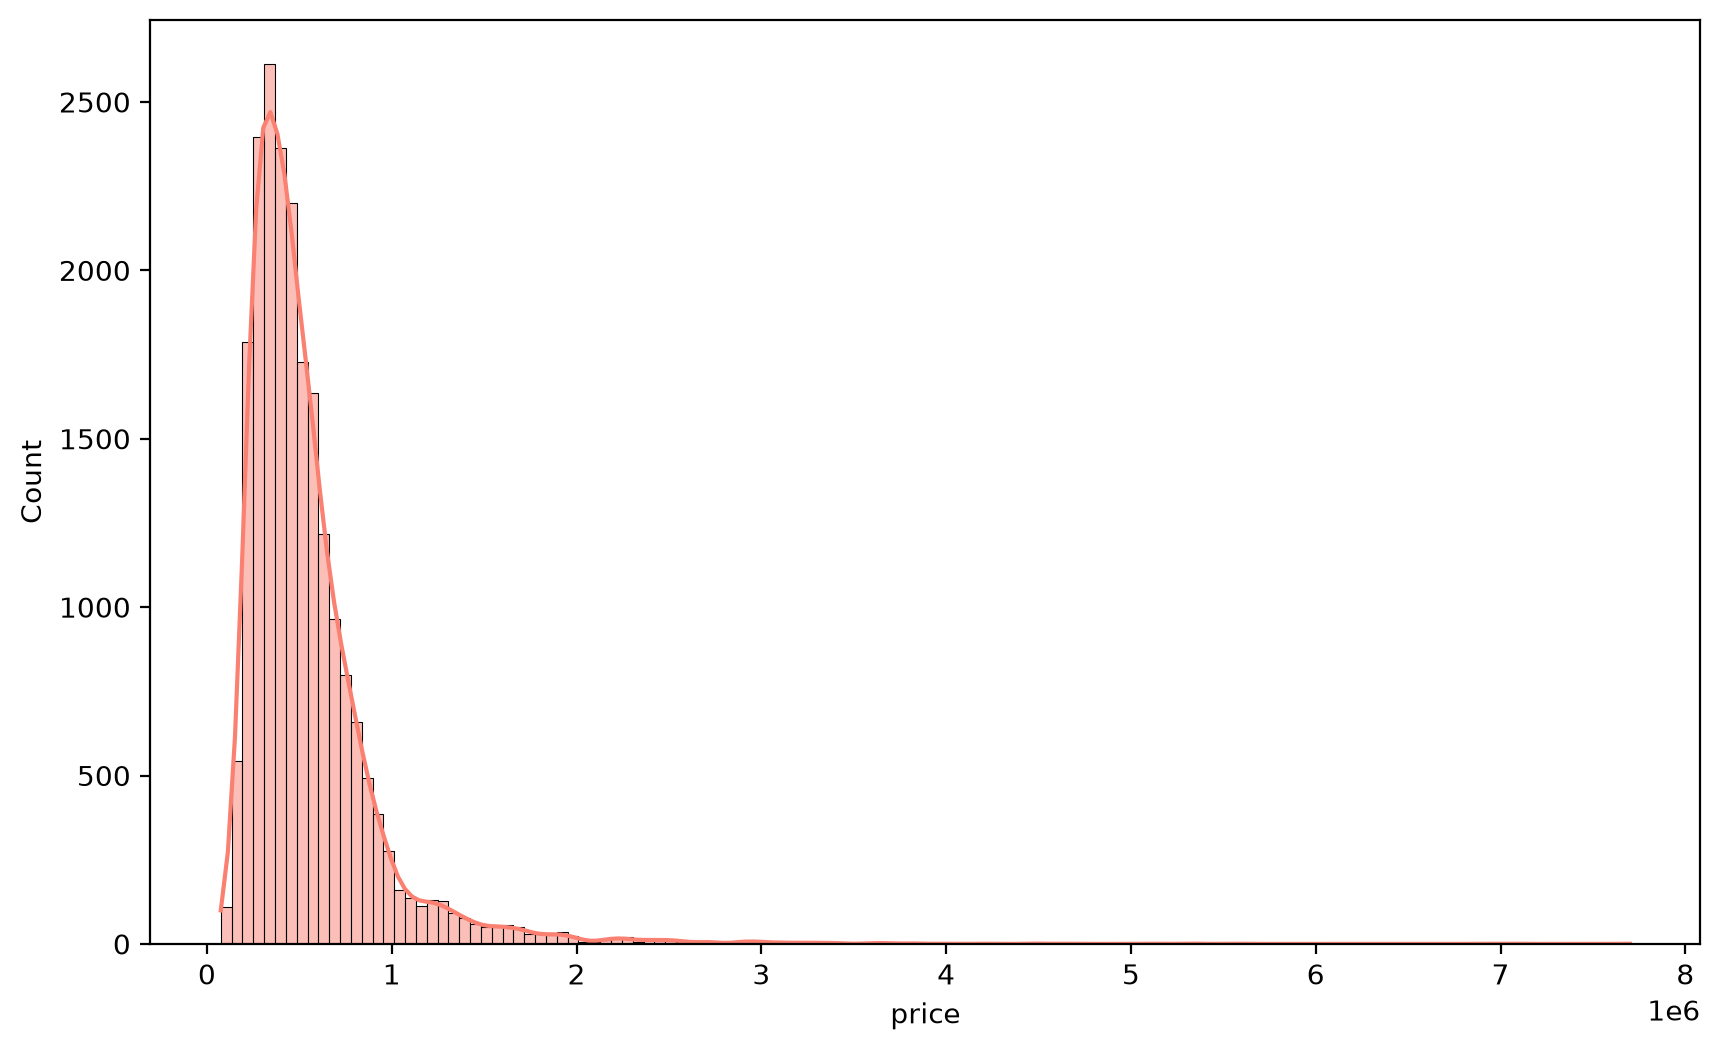

In [14]:
fig , ax = plt.subplots(figsize = (10,6))
sns.histplot(x = df.price, 
             kde = True, 
             bins = 130 , 
             color = 'salmon');

In [15]:
df.price.describe()

count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [16]:
(df.price>4e+06).sum()

np.int64(11)

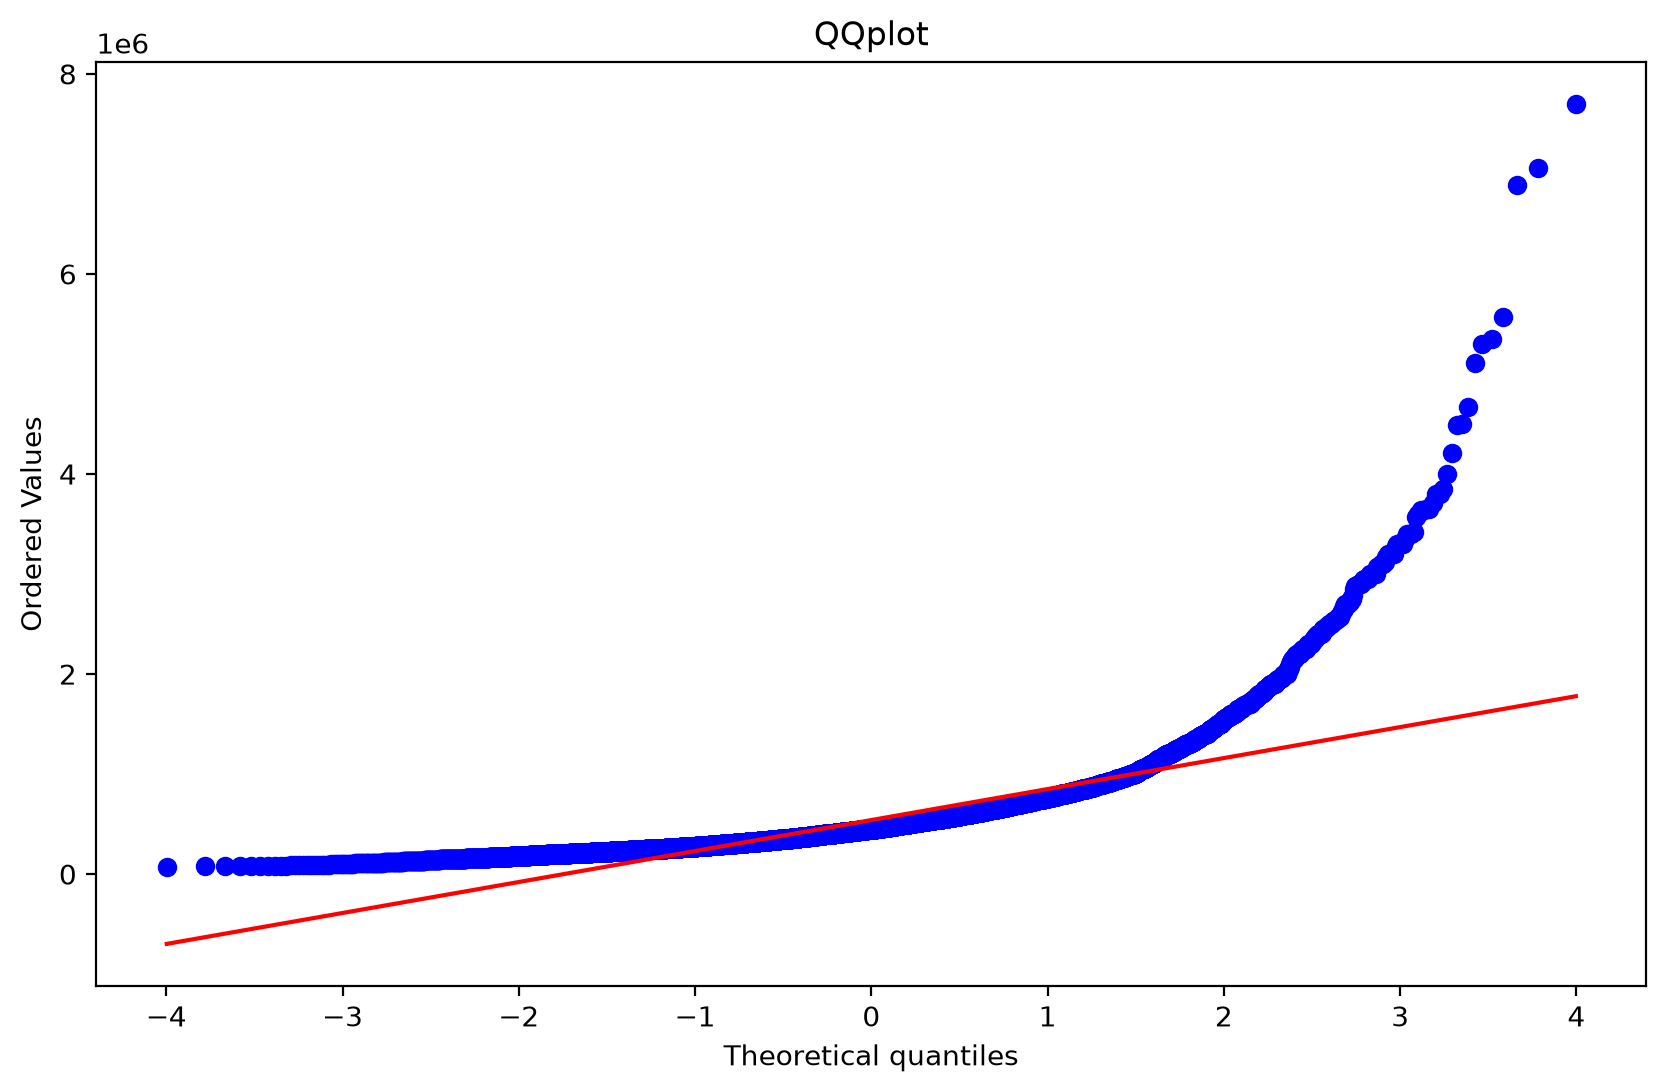

In [17]:
# checking for qq plot 
fig, ax = plt.subplots(figsize = (10,6))
stats.probplot(df.price, dist = 'norm', plot = ax)
ax.set_title('QQplot');

> With this we confirmed that the price is right skewed which we will have to fix, by removing outliers and transforming it to make little bit normally distributed

> **$BEDROOMS$**

In [18]:
# bedrooms 
df.bedrooms.value_counts()

bedrooms
3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

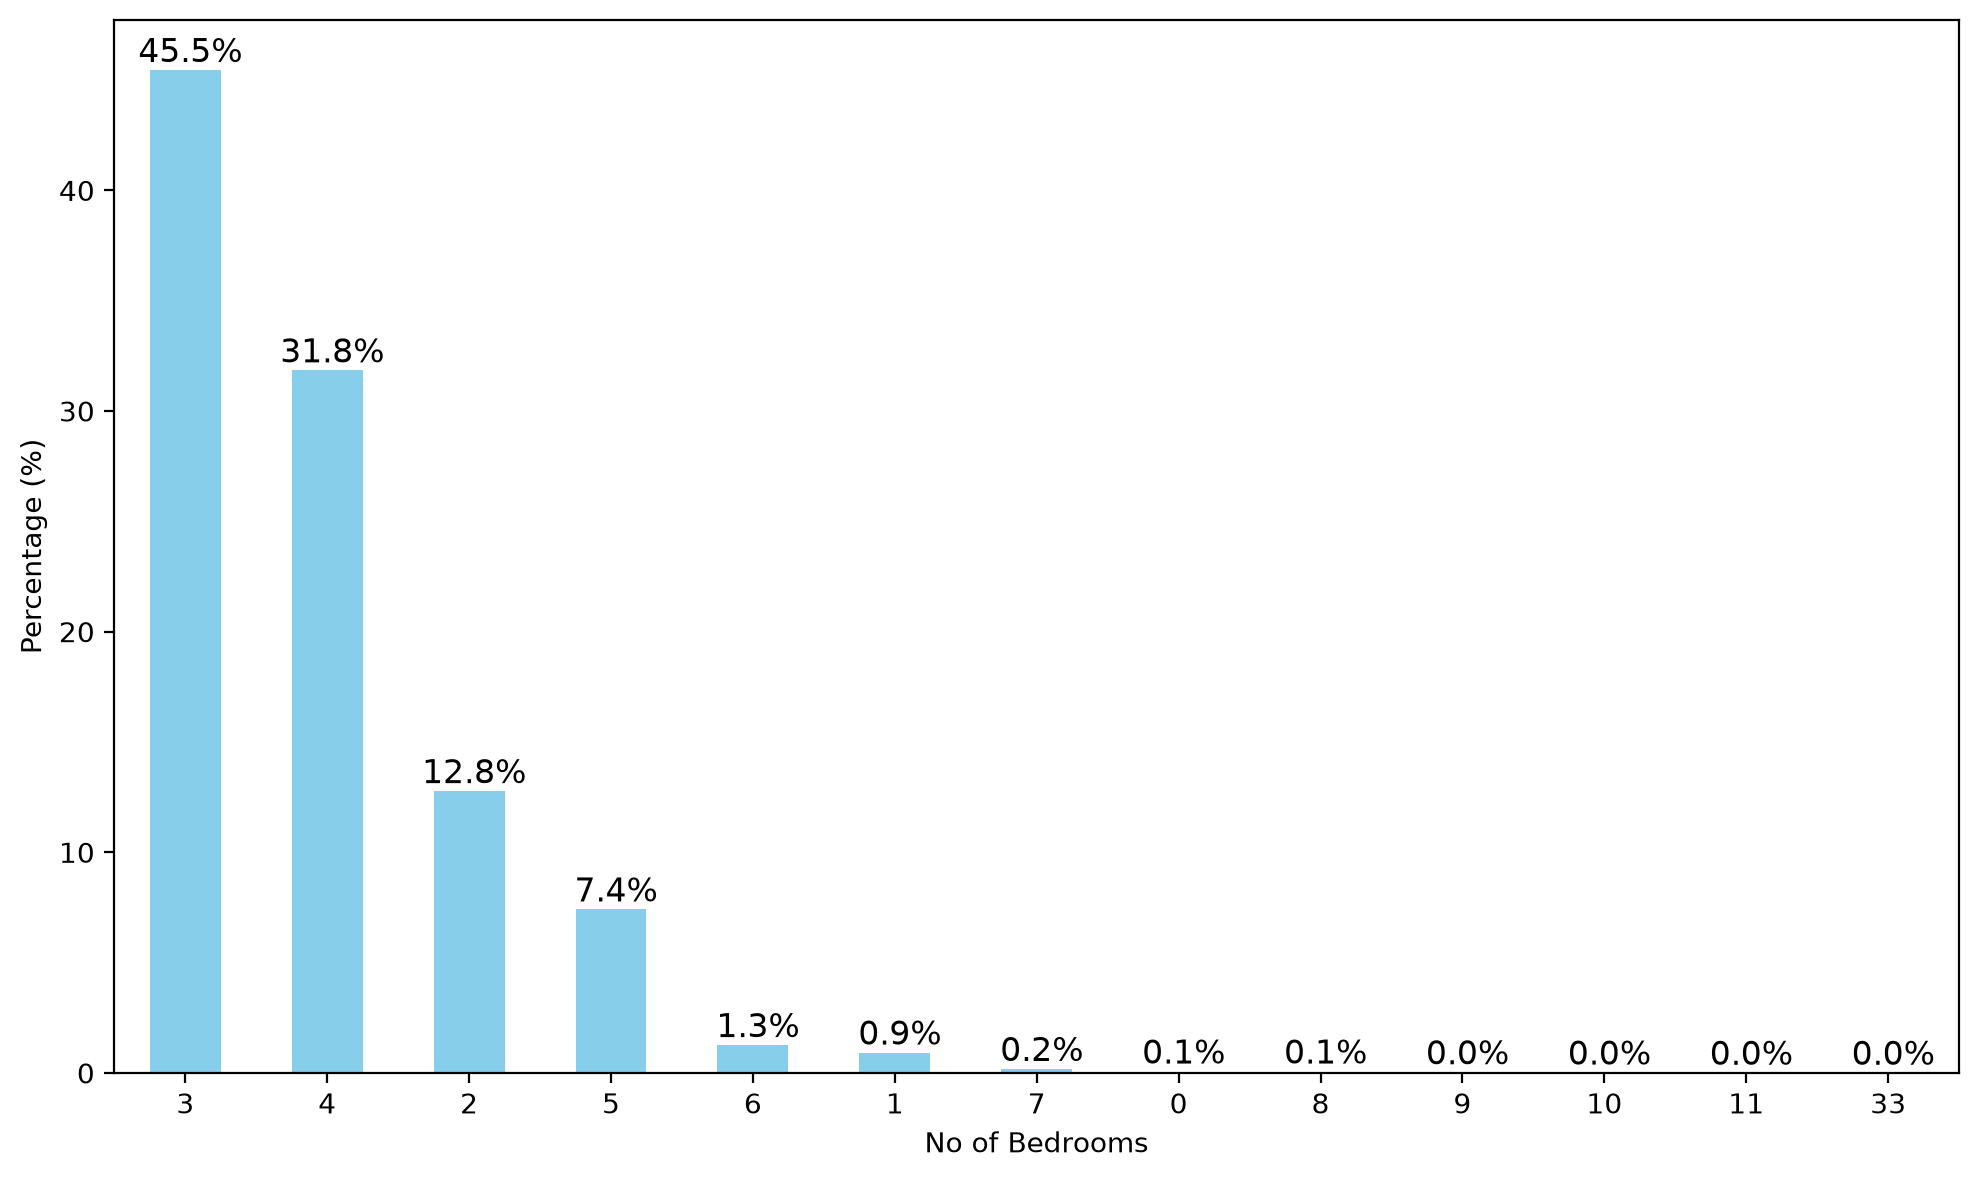

In [19]:
per = df.bedrooms.value_counts(normalize= True) * 100

fig, ax = plt.subplots(figsize = (10,6))
per.plot(kind = 'bar', color = 'skyblue')
plt.ylabel('Percentage (%)')
plt.xlabel('No of Bedrooms')

# annotate each bar 
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height: .1f}%',
               (p.get_x() + p.get_width()/2, height),
               ha = 'center', va = 'bottom', fontsize = 12)
plt.xticks(rotation = 0) 
plt.tight_layout()
plt.show()

> There are some outliers which we will have to remove 

>**$BATHROOM$**

In [20]:
df.bathrooms.value_counts()

bathrooms
2.50    5380
1.00    3852
1.75    3048
2.25    2047
2.00    1930
1.50    1446
2.75    1185
3.00     753
3.50     731
3.25     589
3.75     155
4.00     136
4.50     100
4.25      79
0.75      72
4.75      23
5.00      21
5.25      13
0.00      10
5.50      10
1.25       9
6.00       6
0.50       4
5.75       4
6.75       2
8.00       2
6.25       2
6.50       2
7.50       1
7.75       1
Name: count, dtype: int64

<Axes: xlabel='bathrooms'>

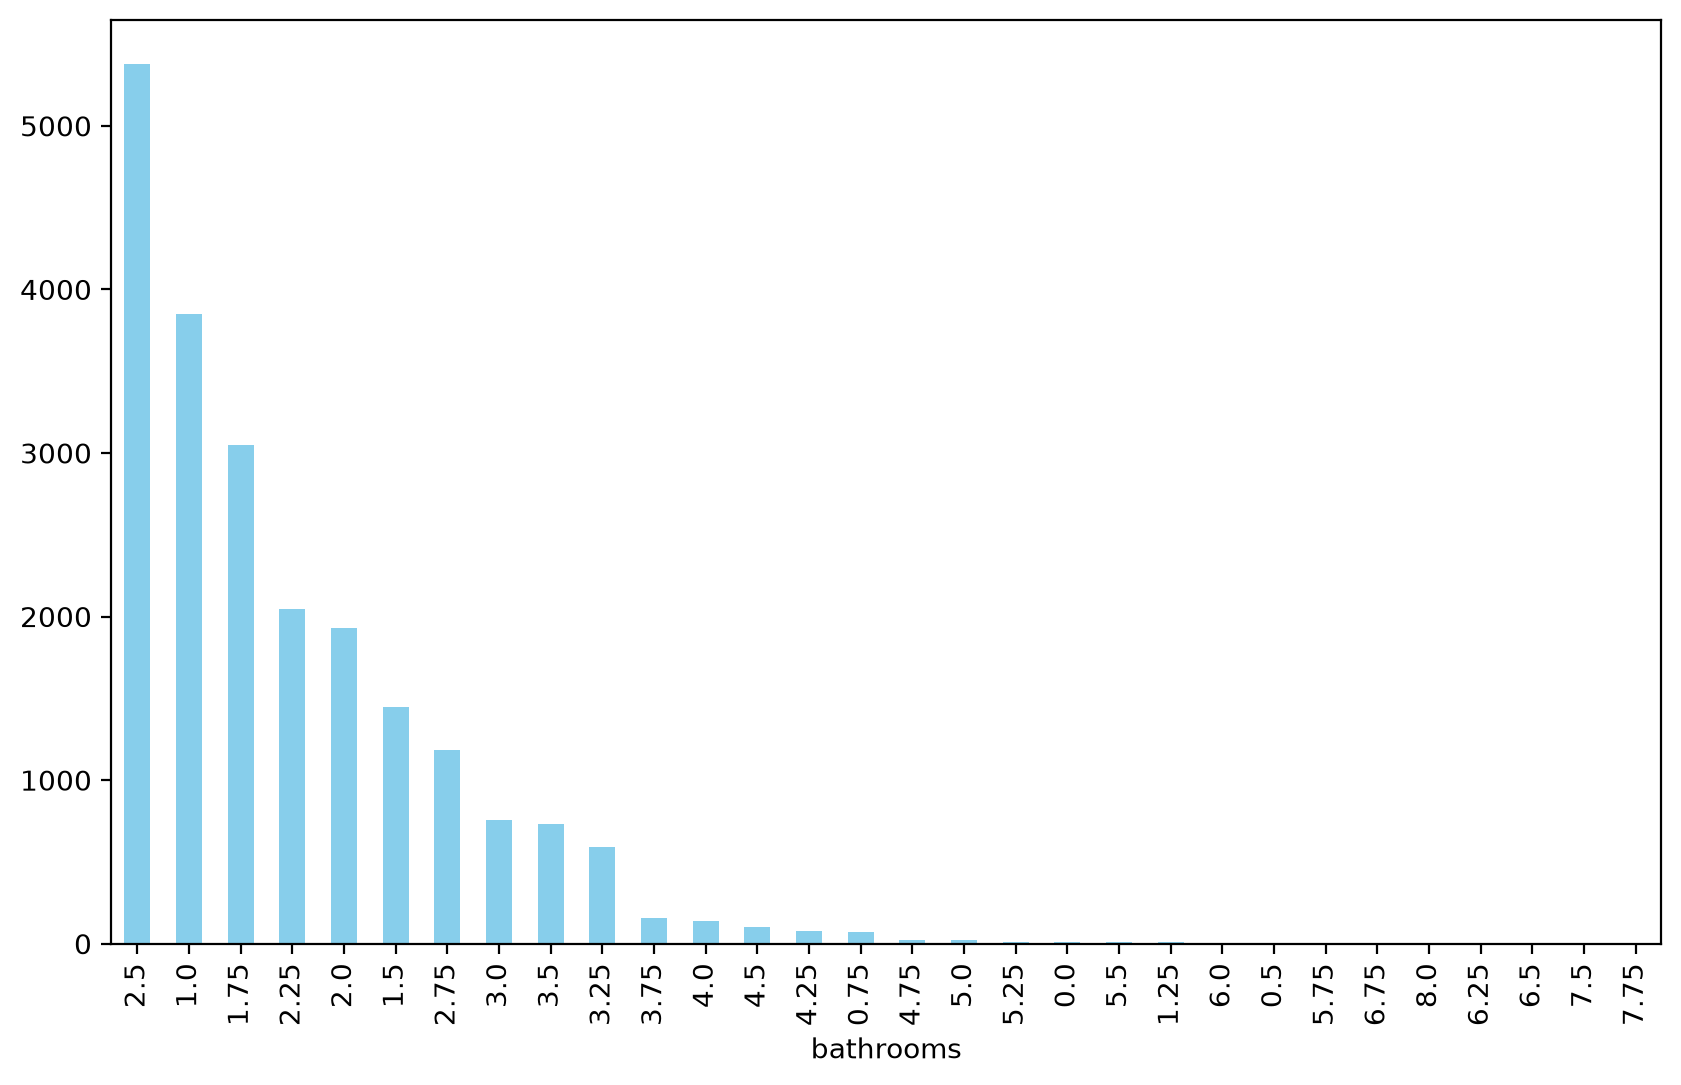

In [21]:
df.bathrooms.value_counts().plot(kind = 'bar', color = 'skyblue', figsize = (10, 6))

> This is also having outliers we will not remove then instead we will group them 

>**$LIVING AREA$**

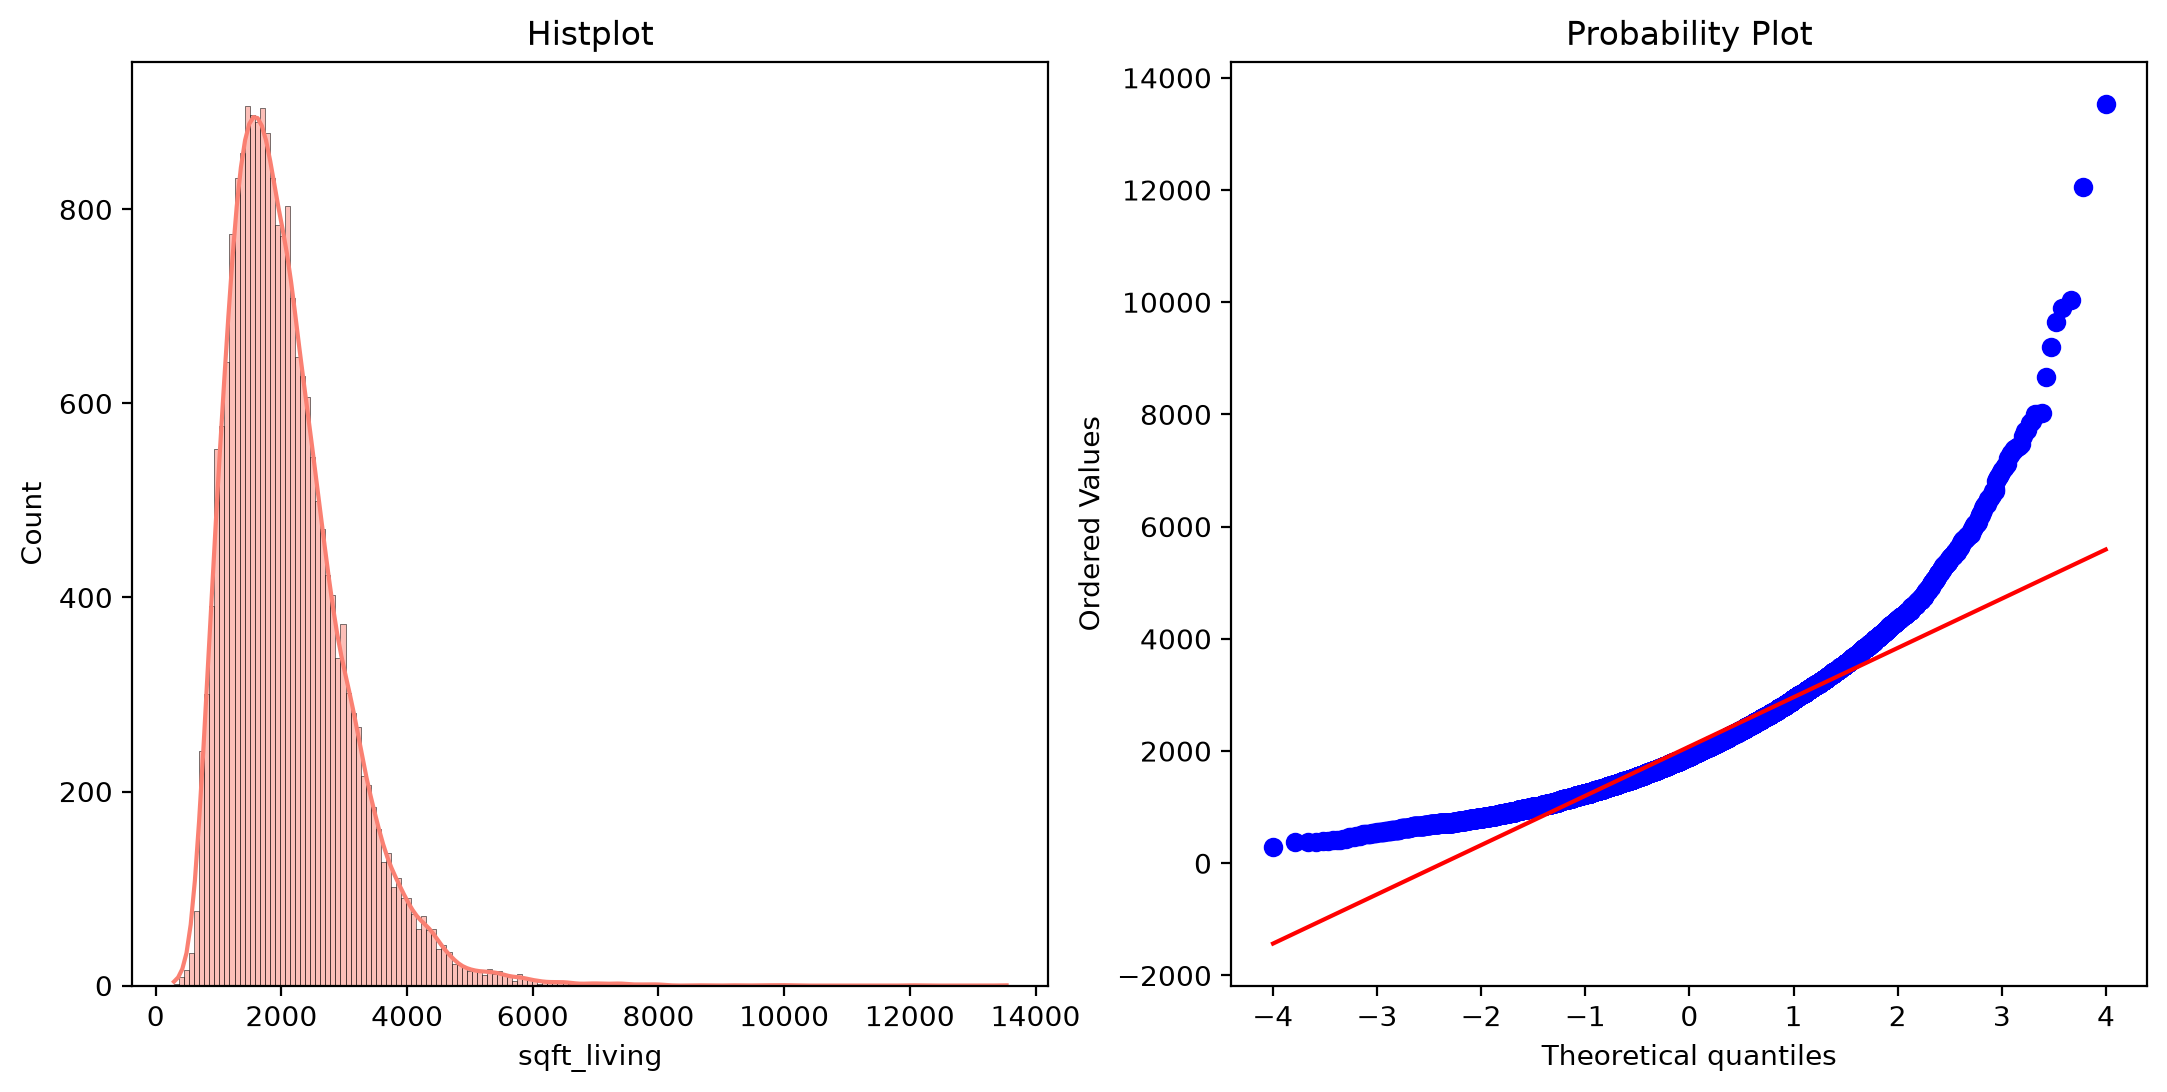

In [22]:
fig , (ax0,ax1) = plt.subplots(figsize = (13,6), ncols = 2)
sns.histplot(df.sqft_living, kde = True , color = 'salmon', ax = ax0)
ax0.set_title('Histplot')
stats.probplot(df.sqft_living, plot = ax1);

> The data is Right skewed we will try making it as normally distributed as much as  possible

In [23]:
# Floors 
df.floors.value_counts()

floors
1.0    10680
2.0     8241
1.5     1910
3.0      613
2.5      161
3.5        8
Name: count, dtype: int64

In [24]:
# Waterfront 
df.waterfront.value_counts()

waterfront
0    21450
1      163
Name: count, dtype: int64

In [25]:
# View 
df.view.value_counts()

view
0    19489
2      963
3      510
1      332
4      319
Name: count, dtype: int64

In [26]:
# Condination 
df.condition.value_counts()

condition
3    14031
4     5679
5     1701
2      172
1       30
Name: count, dtype: int64

In [27]:
# Grade 
df.grade.value_counts()

grade
7     8981
8     6068
9     2615
6     2038
10    1134
11     399
5      242
12      90
4       29
13      13
3        3
1        1
Name: count, dtype: int64

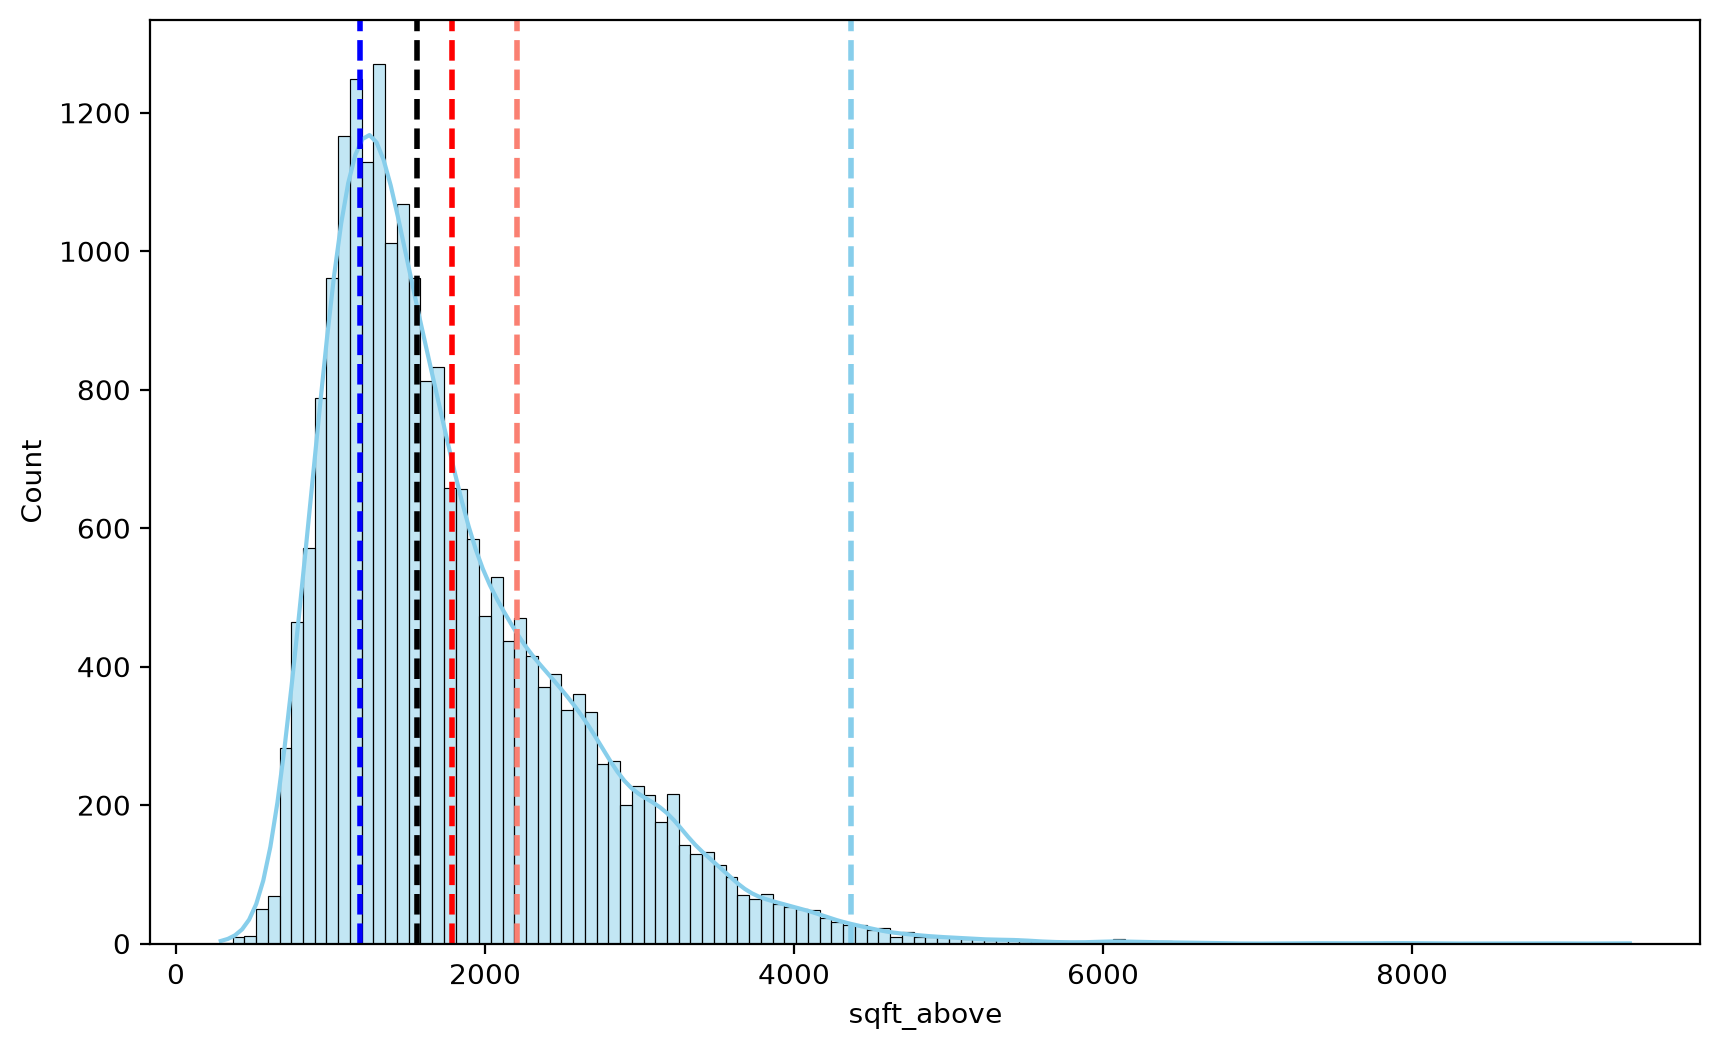

In [28]:
# Area above 
fig, ax = plt.subplots(figsize = (10, 6))
sns.histplot(df.sqft_above, kde = True , color= 'skyblue', bins = 120)

# Complete statistics 
mean_val = df.sqft_above.mean()
median_val = df.sqft_above.median()
q25 = df.sqft_above.quantile(0.25)
q75 = df.sqft_above.quantile(0.75)
q99 = df.sqft_above.quantile(0.99)

# draw vertical lines 
ax.axvline(mean_val, color = 'red', linestyle = '--', linewidth = 2, label = f'Mean({mean_val:.2f})')
ax.axvline(median_val, color = 'black', linestyle = '--', linewidth = 2, label = f'Median({median_val:.2f})')
ax.axvline(q25, color = 'blue', linestyle = '--', linewidth = 2, label = f'25% ({q25:.2f})')
ax.axvline(q75, color = 'salmon', linestyle = '--', linewidth = 2, label = f'75% ({q75:.2f})')
ax.axvline(q99, color = 'skyblue', linestyle = '--', linewidth = 2, label = f'99% ({q99:.2f})');

Text(0.5, 1.0, 'QQ plot of Sqft Above')

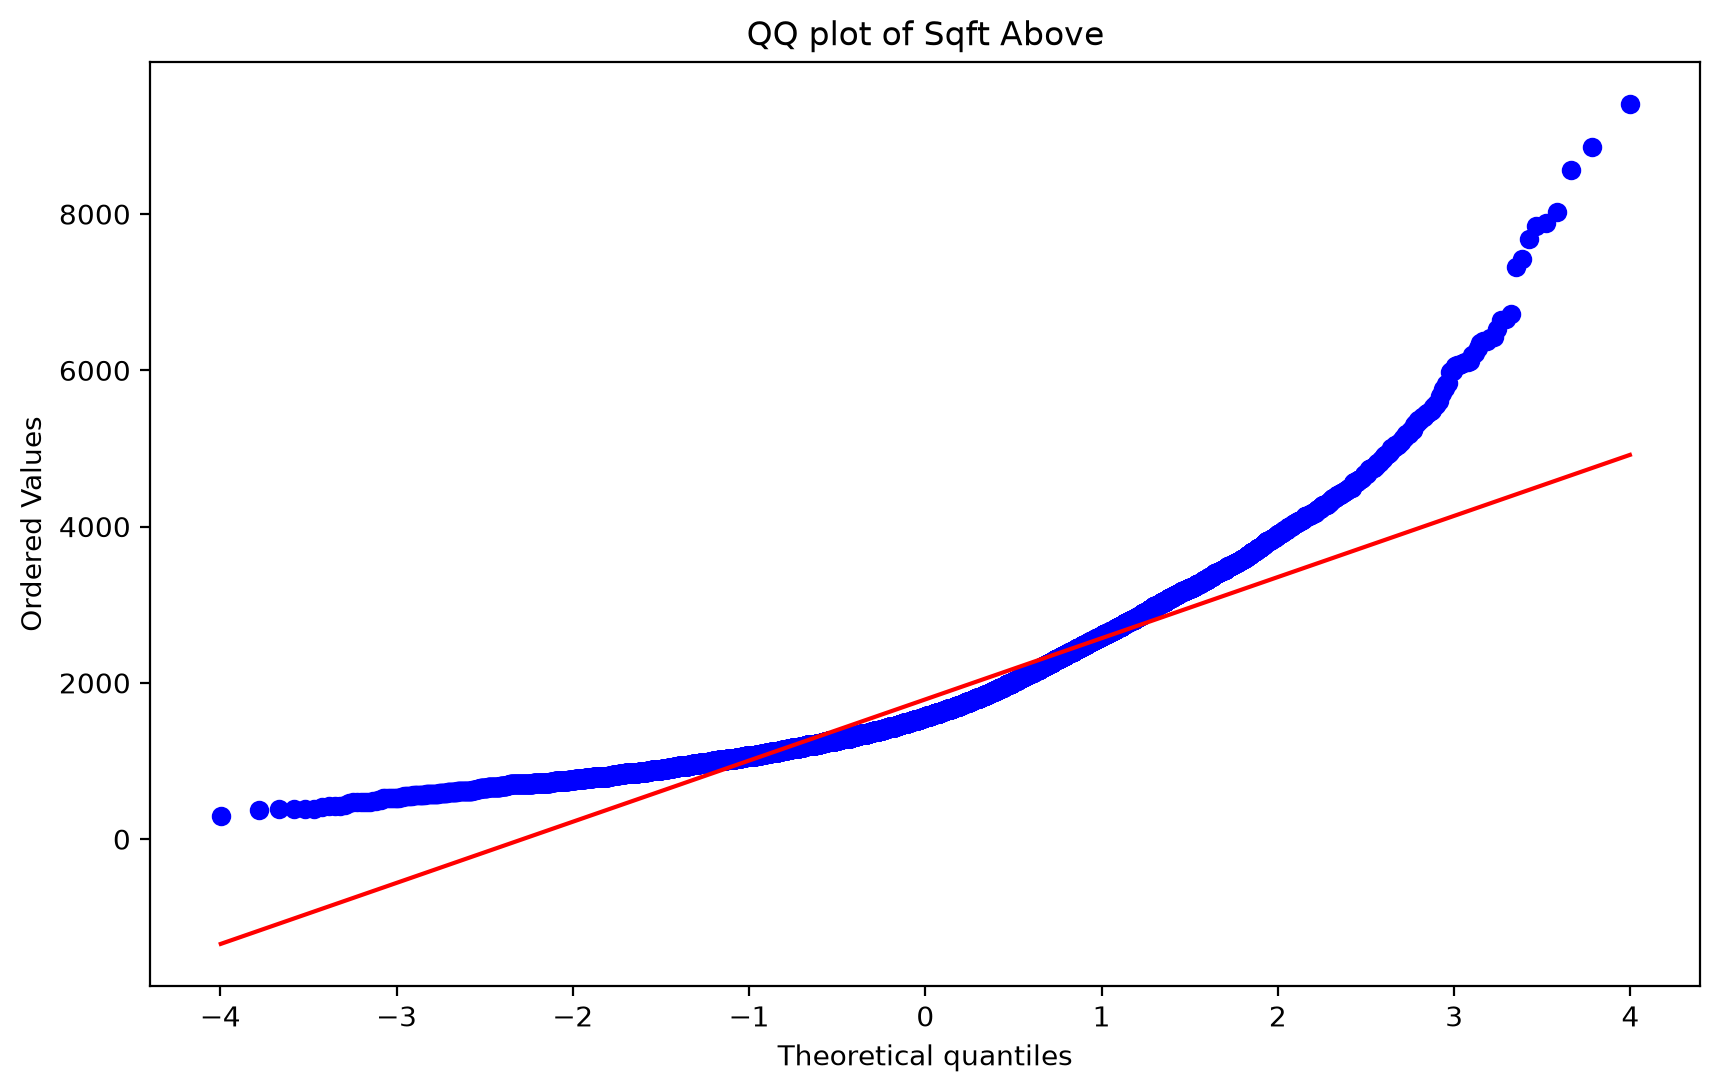

In [29]:
fig, ax = plt.subplots(figsize = (10,6))
stats.probplot(df.sqft_above, dist = 'norm', plot = ax)
plt.title('QQ plot of Sqft Above')

>Right skewed this need to be normalized\
If mean > median → right‑skewed.\
If mean < median → left‑skewed.

#### **Creating the map using lat and long**

In [30]:
# Lat and Long ploting both together 
# computing mean coordinates
mean_lat = df.lat.mean()
mean_long = df.long.mean()

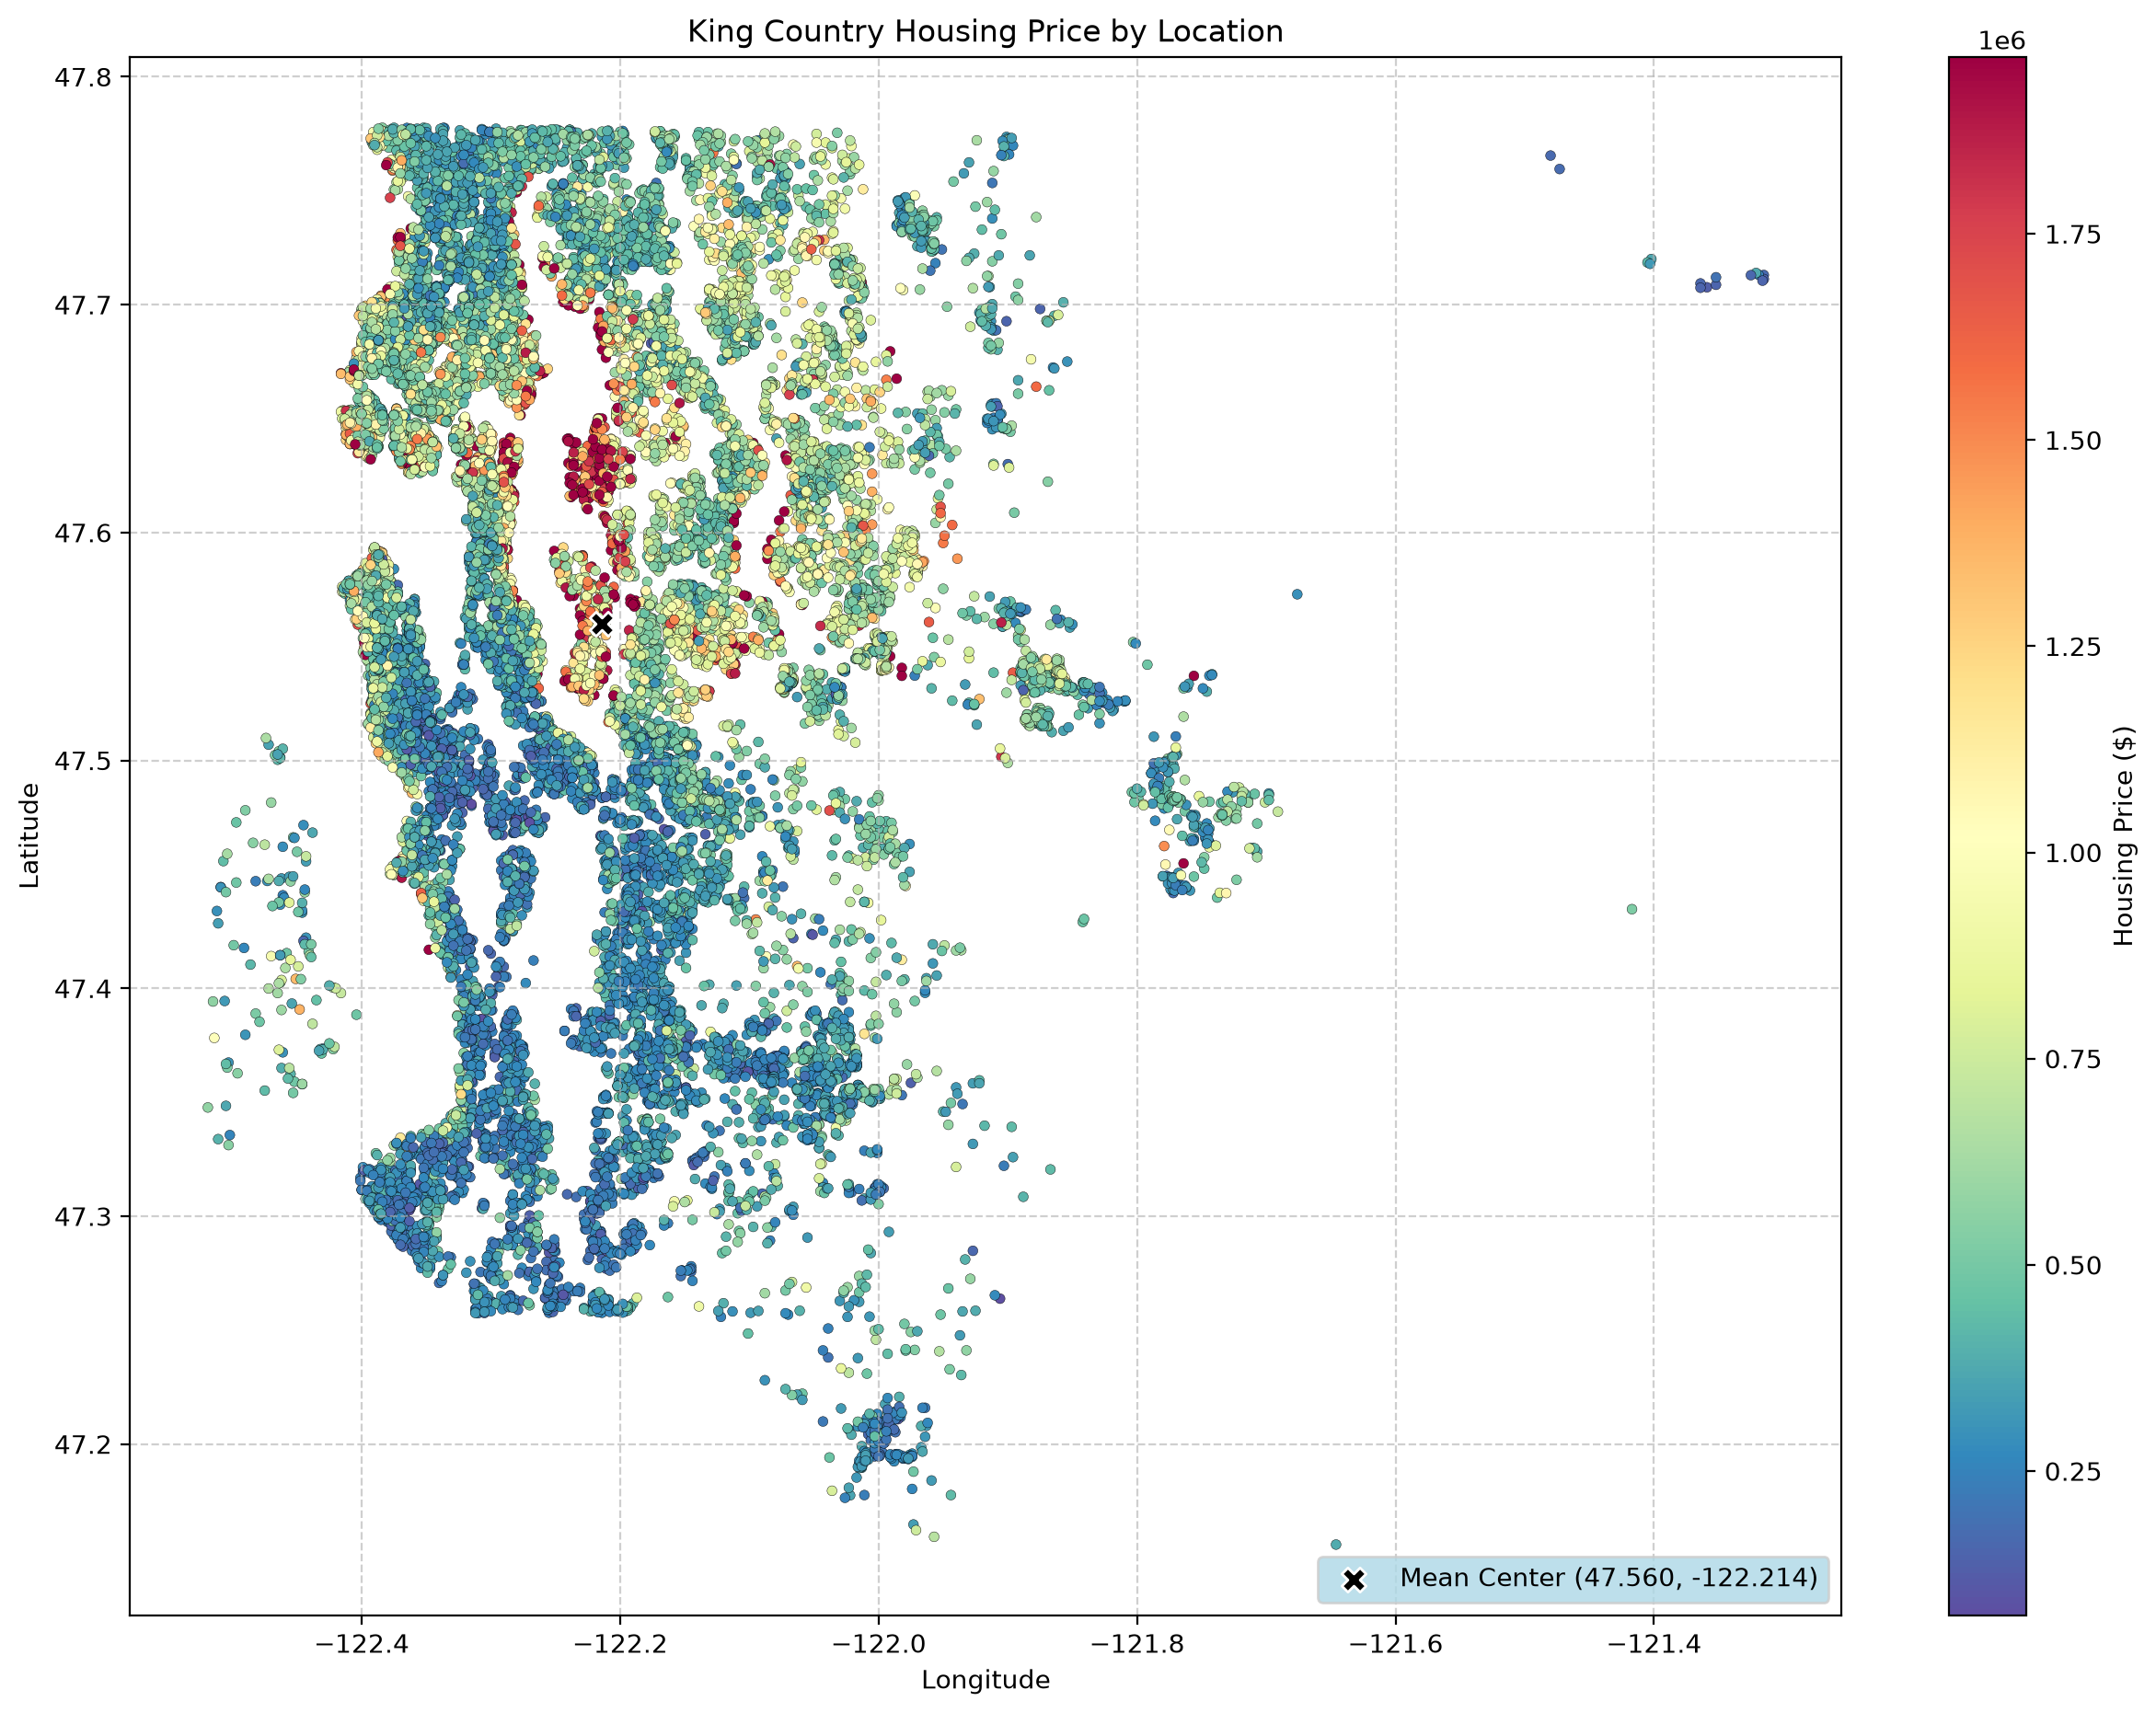

In [31]:
# plotting the location of houses 
fig, ax = plt.subplots(figsize = (15,11))
scatter = ax.scatter(x = df.long, 
            y = df.lat,
            c = df.price,
            cmap = 'Spectral_r',
            s = 15,
            edgecolor = 'black',
            linewidths= .15,
            alpha = 1,
            vmax= df.price.quantile(0.99)
                    )

# overlay mean marker
ax.scatter(mean_long, 
           mean_lat,
           color = 'black',
           marker = 'X',
           s = 90, 
           zorder = 5 ,
           edgecolor = 'white', 
           linewidths = 1,
           label = f'Mean Center ({mean_lat:.3f}, {mean_long:.3f})'
          )

# showing the plot 
plt.colorbar(scatter, ax = ax , label = 'Housing Price ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('King Country Housing Price by Location')
plt.legend(loc = 'lower right', frameon = True, facecolor = 'lightblue')
plt.grid(True , linestyle = '--', alpha = .6)
plt.savefig('my_plot.svg', bbox_inches = 'tight')
plt.show()

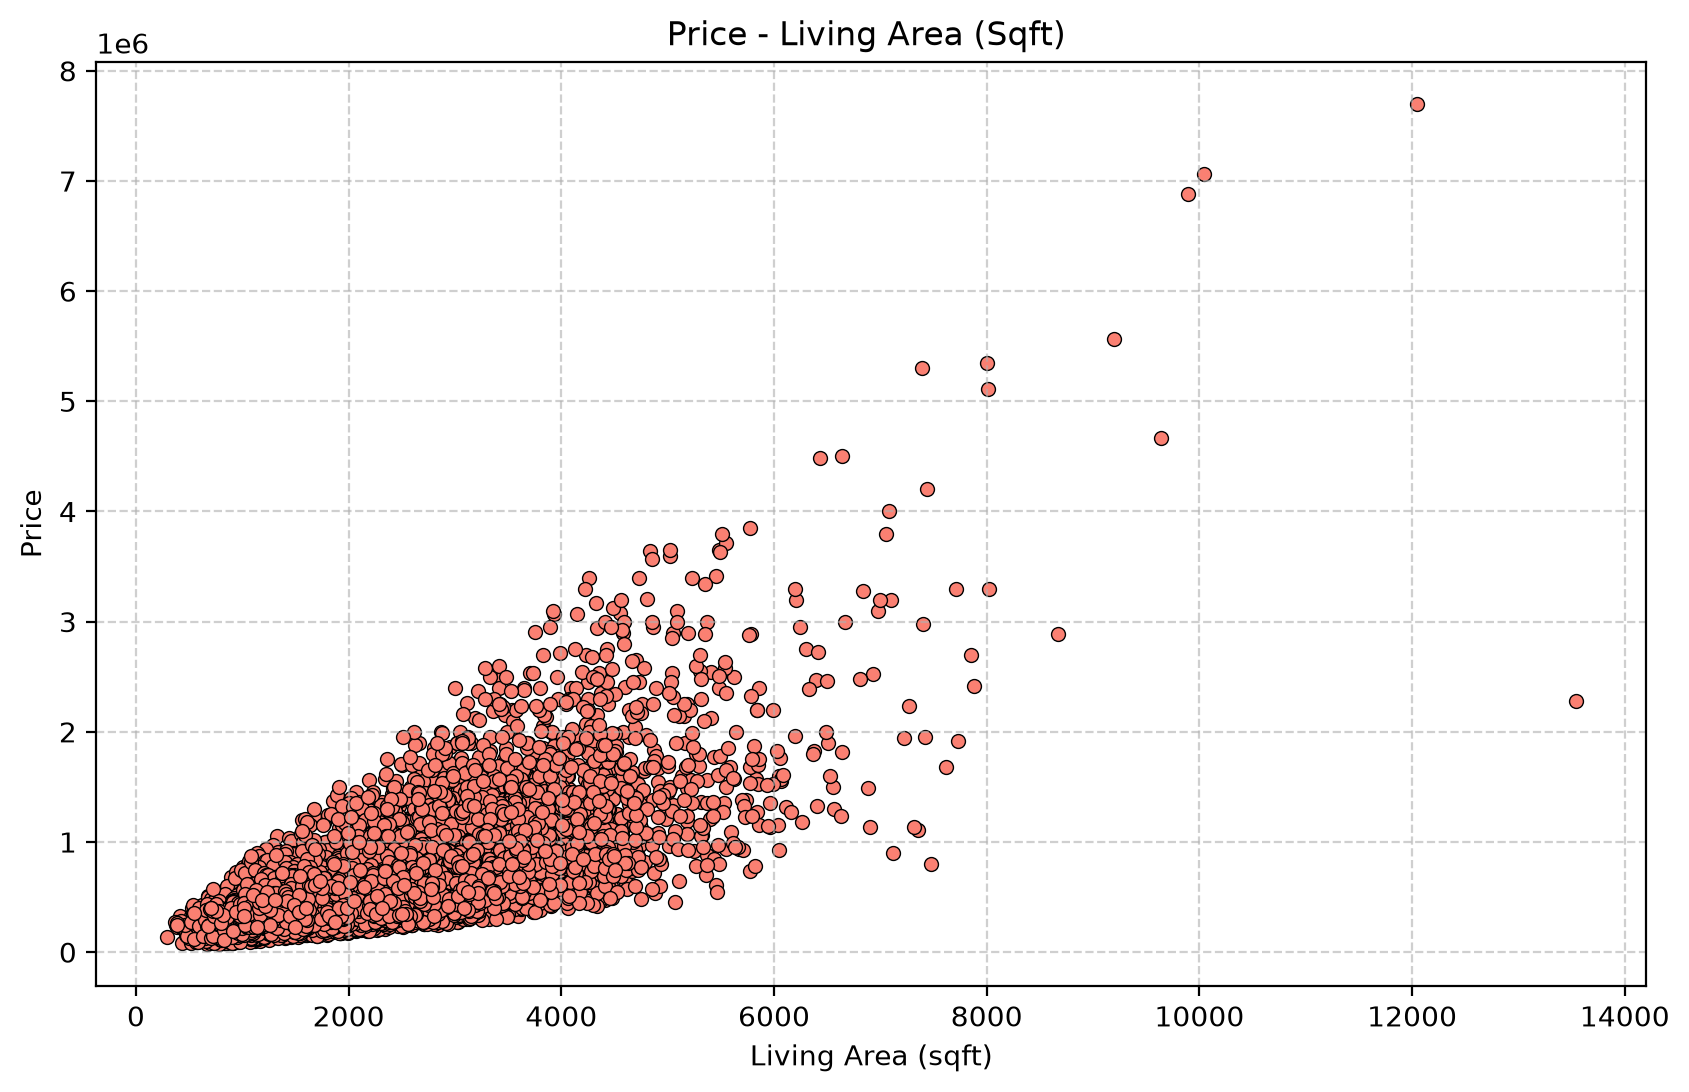

In [32]:
# Price - Living area
fig, ax = plt.subplots(figsize = (10,6))
plt.scatter(df.sqft_living, 
            df.price,
            color = 'salmon',
            s = 25, 
            edgecolors= 'black',
            linewidths= .5,
           )
plt.xlabel('Living Area (sqft)')
plt.ylabel('Price')
plt.title('Price - Living Area (Sqft) ')
plt.grid(True, alpha = .6, linestyle= '--')

plt.show()

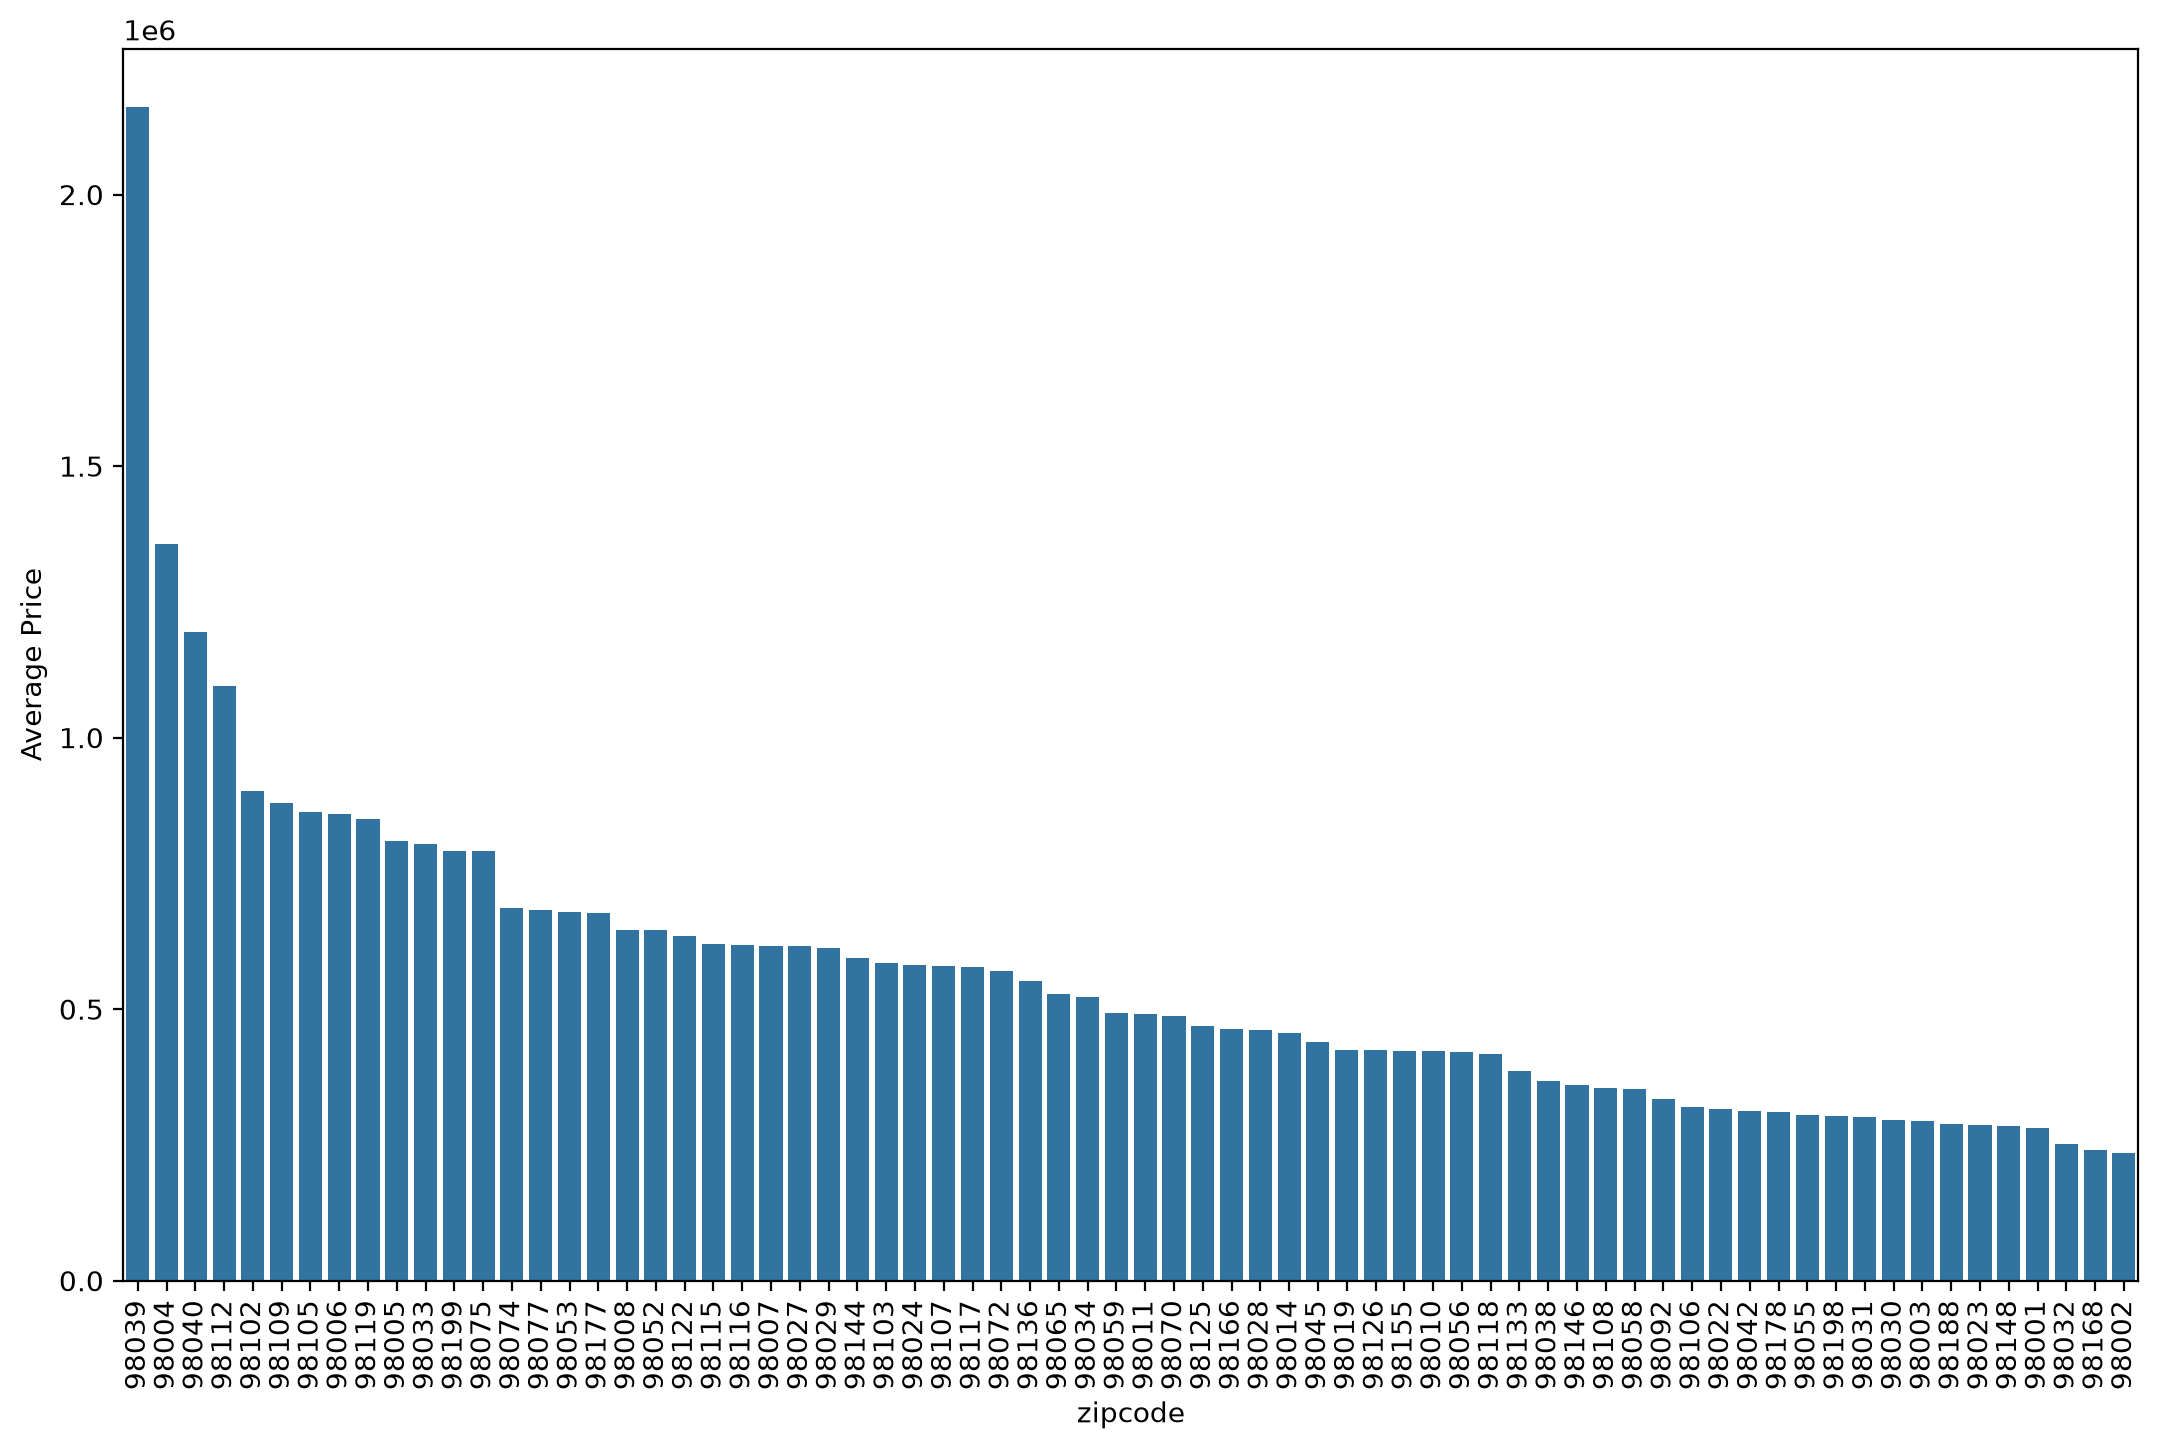

In [33]:
# Price - Zip code (Average price per zipcode)
zip_price = (df.groupby('zipcode')['price'].mean().sort_values(ascending = False))

fig, ax = plt.subplots(figsize = (13,8))
sns.barplot(x= zip_price.index.astype(str), 
           y= zip_price.values)
plt.xticks(rotation = 90)
plt.ylabel('Average Price')
plt.show()

## 4. Transforming the dataset

In [34]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,2014,59
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,2014,63
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2015,82
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,2014,49
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,2015,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,2014,5
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,2015,1
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,2014,5
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,2015,11


In [35]:
# Bedroom 

# deleting the extreme outlier
df = df[df.bedrooms != 33]

# bedrooms > 8 = 8 
df.loc[df.bathrooms > 8 , 'bedrooms'] = 8 

# bathrooms > 6 = 6 
df.loc[df.bathrooms > 6, 'bathrooms'] = 6

# bathrooms between 5 to 6 = 5 
df.loc[(df.bathrooms > 5) & (df.bathrooms < 6 ), 'bathrooms'] = 5

# floors above 3 = 3 
df.loc[df.floors > 3, 'floors'] = 3


In [36]:
df.floors.value_counts()

floors
1.0    10679
2.0     8241
1.5     1910
3.0      621
2.5      161
Name: count, dtype: int64

In [37]:
df.bedrooms.value_counts()

bedrooms
3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
11       1
Name: count, dtype: int64

In [38]:
df_main = df.copy()
df_main

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,2014,59
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,2014,63
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2015,82
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,2014,49
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,2015,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,2014,5
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,2015,1
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,2014,5
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,2015,11


In [39]:
# Selecting the top 1% of higest-priced sales 
top_expensive = df.nlargest(int(len(df)*0.01), 'price')
top_expensive

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age
7252,7700000.0,6,6.0,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,2014,104
3914,7062500.0,5,4.5,10040,37325,2.0,1,2,3,11,7680,2360,1940,2001,98004,47.6500,-122.214,2014,74
9254,6885000.0,6,6.0,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,2014,13
4411,5570000.0,5,5.0,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,2014,13
1448,5350000.0,5,5.0,8000,23985,2.0,0,4,3,12,6720,1280,2009,0,98004,47.6232,-122.220,2015,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16525,1980000.0,4,3.5,4500,44384,1.0,0,0,3,12,3340,1160,1990,0,98004,47.6323,-122.192,2015,25
19529,1980000.0,4,4.0,4360,12081,2.0,0,0,3,10,4360,0,2007,0,98004,47.6377,-122.219,2014,7
7415,1975000.0,6,4.5,4800,9097,2.0,0,0,3,10,3580,1220,2007,0,98112,47.6259,-122.291,2014,7
17235,1970000.0,8,3.5,4440,6480,2.0,0,3,5,10,3140,1300,1959,0,98112,47.6310,-122.303,2014,55


In [40]:
# Select top 1% highest-priced sales
top_expensive = df.nlargest(int(len(df) * 0.01), "price")

center_lat = top_expensive["lat"].mean()
center_long = top_expensive["long"].mean()

In [41]:
def distance(lat1, long1, lat2, long2):
    '''
    Calculate the great circle distance (in km) beteween two points on the earth using vectorized numpy.
    '''

    R = 6371  # Earth radius in km 

    # Convert degree to radian 
    lat1, long1 , lat2, long2 = map(np.radians, [lat1, long1, lat2, long2])

    dlat = lat2 - lat1 
    dlong = long2 - long1

    a = (
        np.sin(dlat/2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlong/2.0) **2
    )
    c = 2 * np.arcsin(np.sqrt(a))

    return R*c

# Add the distance column (in KM)
df['dist_to_luxury_center (KM)'] = distance(df['lat'], df['long'], center_lat, center_long)

Normally, if you want the distance between two points on a flat piece of paper, you use the standard Pythagorean formula:$$\text{distance} = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$
This formula fails on Earth for two reasons:
1. The Earth is a curved sphere: Walking in a straight line on Earth means traveling along a curve.
2. Longitude lines shrink: One degree of latitude is roughly the same everywhere (~111 km). But longitude lines get closer and closer together as you get nearer the North or South Pole. At the Equator, $1^\circ$ of longitude is ~111 km; up in Washington State ($47.6^\circ\text{N}$), $1^\circ$ of longitude is only ~75 km.

The Haversine formula calculates the true straight-line surface distance (called the Great Circle distance) between two coordinates on a sphere.

> **Understanding the code**\
R = 6371. This is the mean radius of Earth in kilometers. If you multiply an angle along a circle (in radians) by the radius of the circle, you get the arc length along the surface:$$\text{arc length} = R \times \theta$$

>lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
>   * Coordinates in datasets are stored in degrees (e.g., $47.6^\circ$).
>   * Python's math and NumPy trigonometric functions (np.sin, np.cos) expect angles in radians.
>   * np.radians(...) converts each degree value to radians ($\text{radians} = \text{degrees} \times \frac{\pi}{180}$).

>a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
>    * This line is the heart of the spherical geometry calculation:
>    * np.sin(dlat / 2.0) ** 2 represents the north-south displacement.
>    * np.sin(dlon / 2.0) ** 2 represents the east-west displacement.
>    * Notice np.cos(lat1) * np.cos(lat2): this is the scaling factor that shrinks east-west distances at higher latitudes. Near the equator, $\cos(0^\circ) = 1$, so you get full distance. Near the poles, $\cos(90^\circ) \approx 0$, shrinking the east-west distance to zero.
>    * Variable a is the square of half the chord length between the two points on a unit sphere.

> The Underlying Function: "Haversine"The name comes from half of a versed sine (an old trigonometric function):$$\text{versin}(\theta) = 1 - \cos(\theta)$$$$\text{hav}(\theta) = \frac{\text{versin}(\theta)}{2} = \frac{1 - \cos(\theta)}{2} = \sin^2\left(\frac{\theta}{2}\right)$$In traditional trigonometry notation, the law of haversines states:$$\text{hav}(c) = \text{hav}(\Delta \text{lat}) + \cos(\text{lat}_1)\cos(\text{lat}_2)\text{hav}(\Delta \text{lon})$$

>If you substitute the identity $\text{hav}(\theta) = \sin^2\left(\frac{\theta}{2}\right)$ into that equation:
>    * $\text{hav}(\Delta \text{lat})$  : : np.sin(dlat / 2.0) ** 2   : :  Haversine of the latitude difference (North-South)
>    * $\cos(\text{lat}_1)\cos(\text{lat}_2)$ :: np.cos(lat1) * np.cos(lat2) :: Correction factor for latitude scaling
>    * $\text{hav}(\Delta \text{lon})$ :: np.sin(dlon / 2.0) ** 2 :: Haversine of the longitude difference (East-West)
>    * $\text{hav}(c)$ :: a  :: The haversine of the central angle between the two points

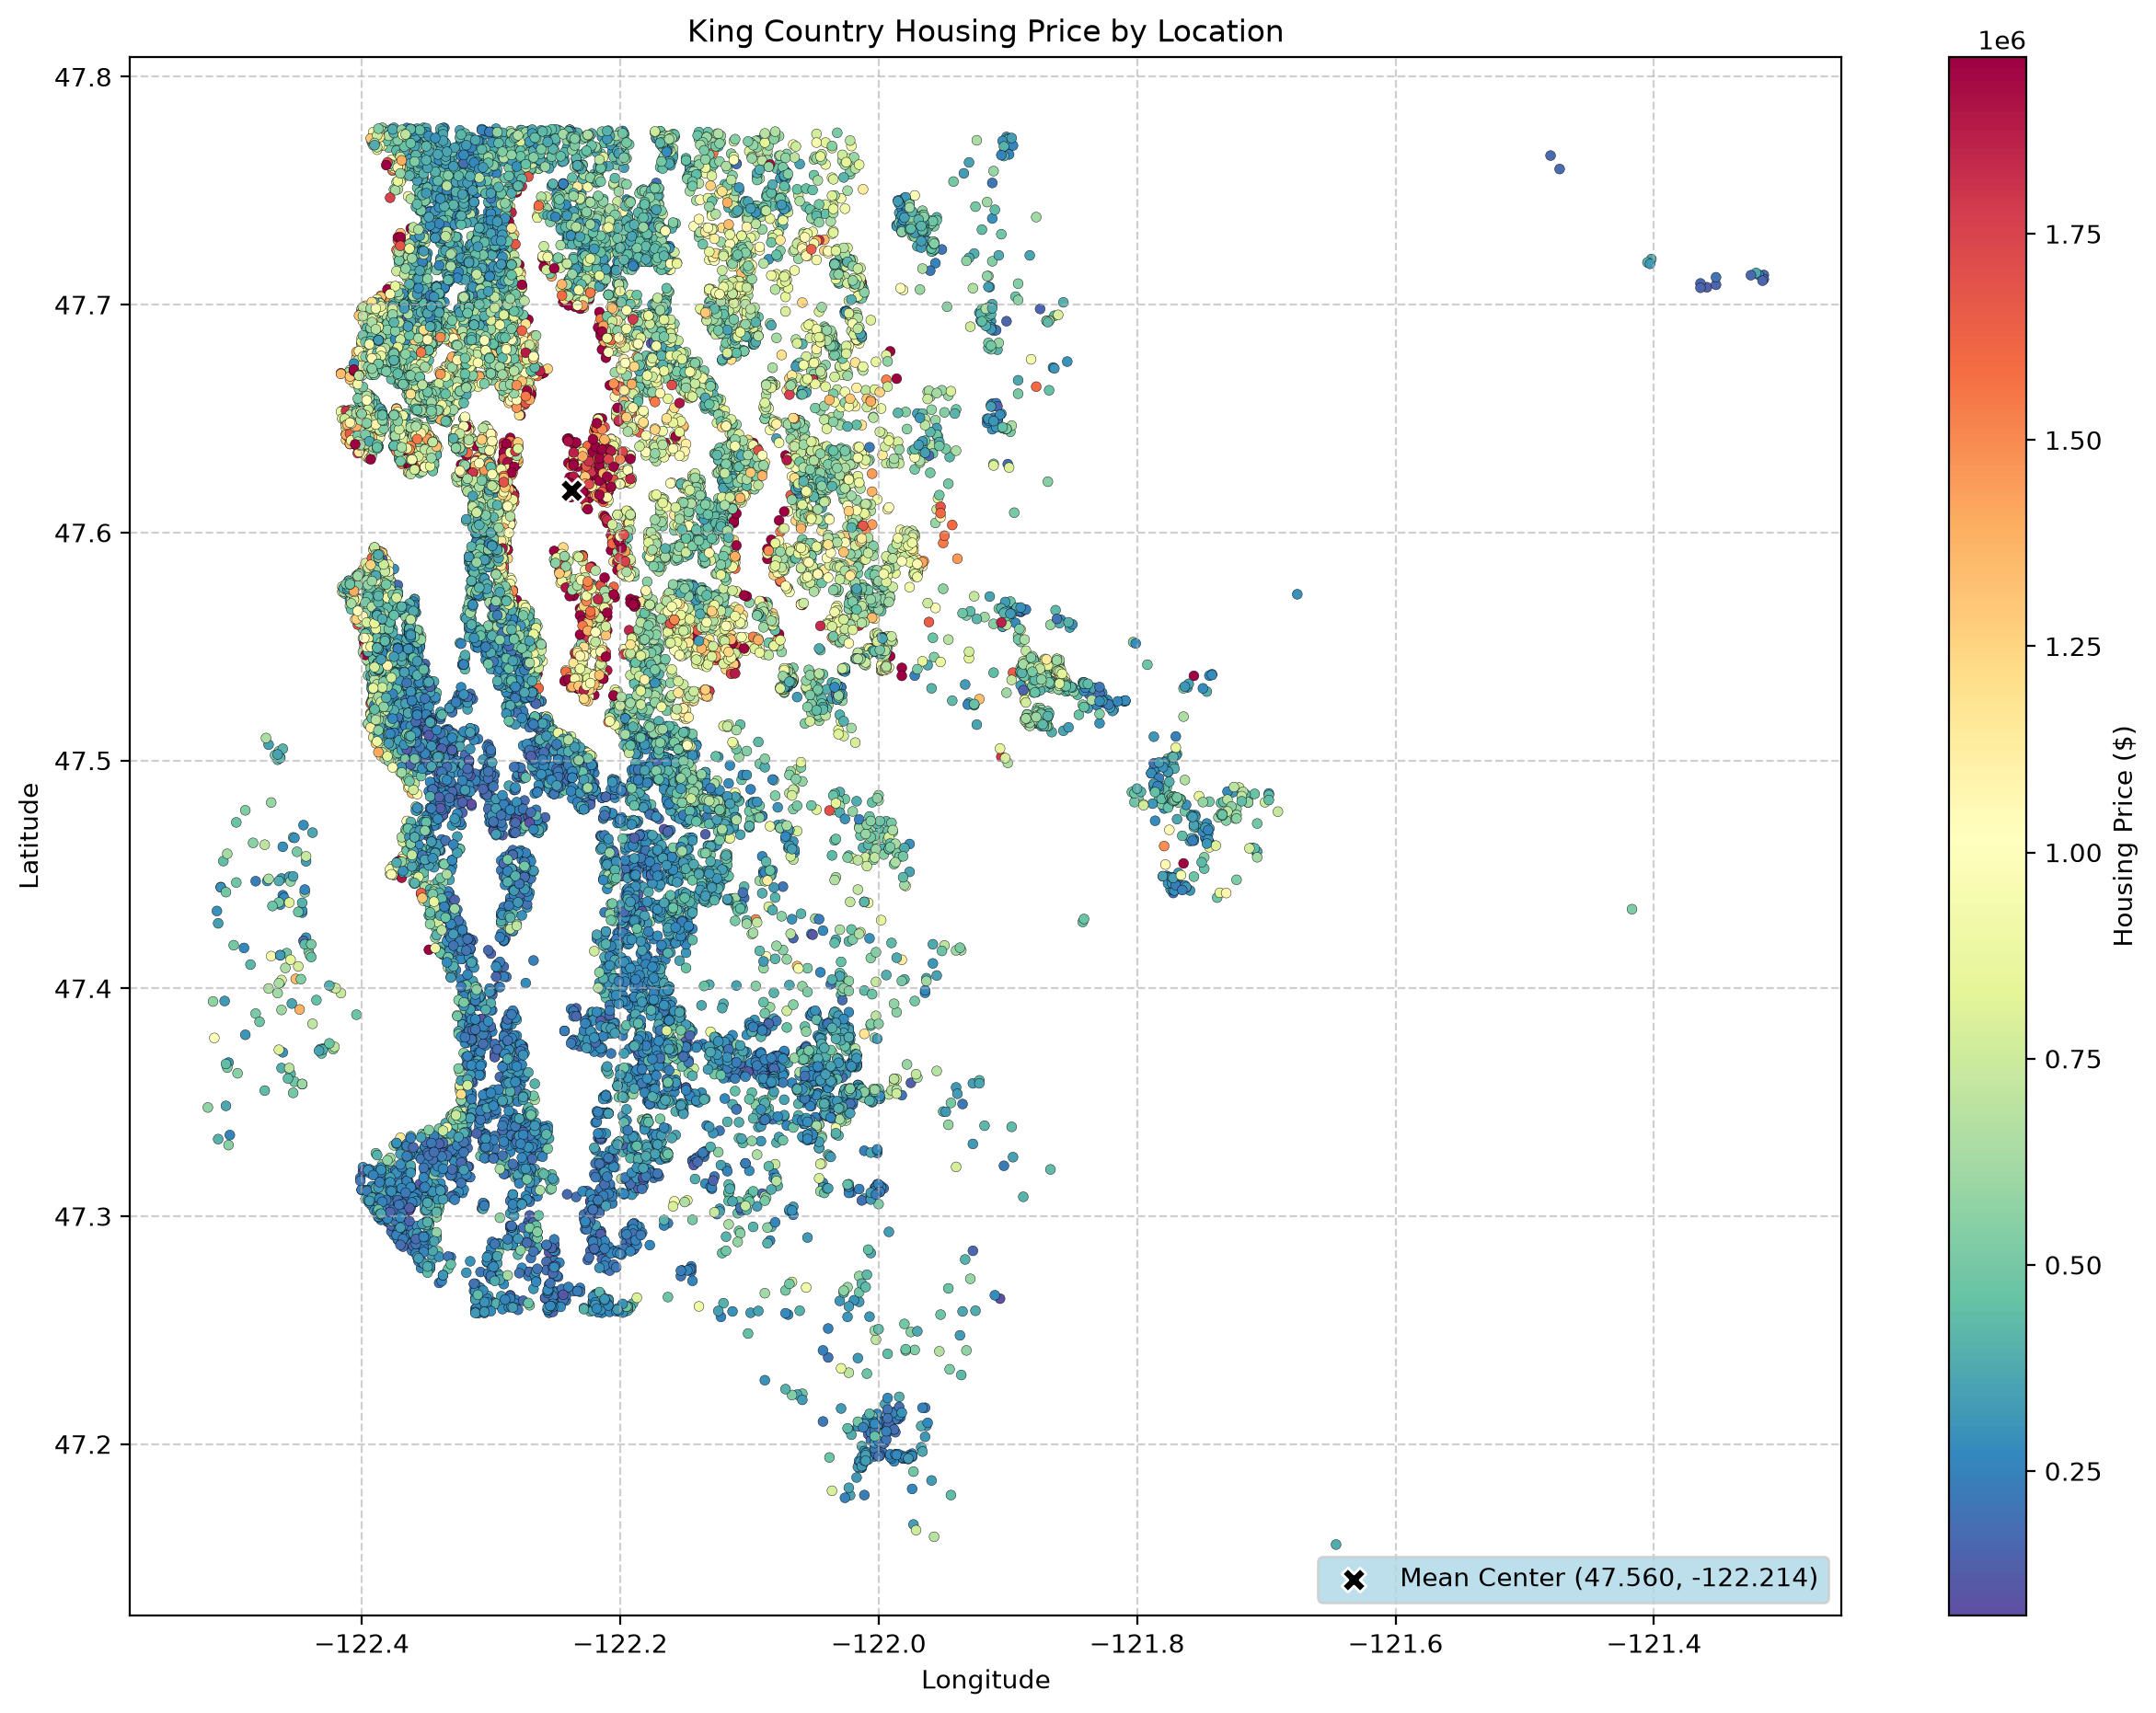

In [42]:
# plotting the location of houses 
fig, ax = plt.subplots(figsize = (15,11))
scatter = ax.scatter(x = df.long, 
            y = df.lat,
            c = df.price,
            cmap = 'Spectral_r',
            s = 15,
            edgecolor = 'black',
            linewidths= .15,
            alpha = 1,
            vmax= df.price.quantile(0.99)
                    )

# overlay mean marker
ax.scatter(center_long, 
           center_lat,
           color = 'black',
           marker = 'X',
           s = 90, 
           zorder = 5 ,
           edgecolor = 'white', 
           linewidths = 1,
           label = f'Mean Center ({mean_lat:.3f}, {mean_long:.3f})'
          )

# showing the plot 
plt.colorbar(scatter, ax = ax , label = 'Housing Price ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('King Country Housing Price by Location')
plt.legend(loc = 'lower right', frameon = True, facecolor = 'lightblue')
plt.grid(True , linestyle = '--', alpha = .6)
plt.savefig('my_plot_expensive.svg', bbox_inches = 'tight')
plt.show()

In [43]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age,dist_to_luxury_center (KM)
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,2014,59,12.034162
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,2014,63,12.903333
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2015,82,13.265123
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,2014,49,15.935705
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,2015,28,14.452580
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,2014,5,12.086941
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,2015,1,15.195854
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,2014,5,5.321655
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,2015,11,15.744222


Text(0.5, 0, 'Distance to luxury center (KM)')

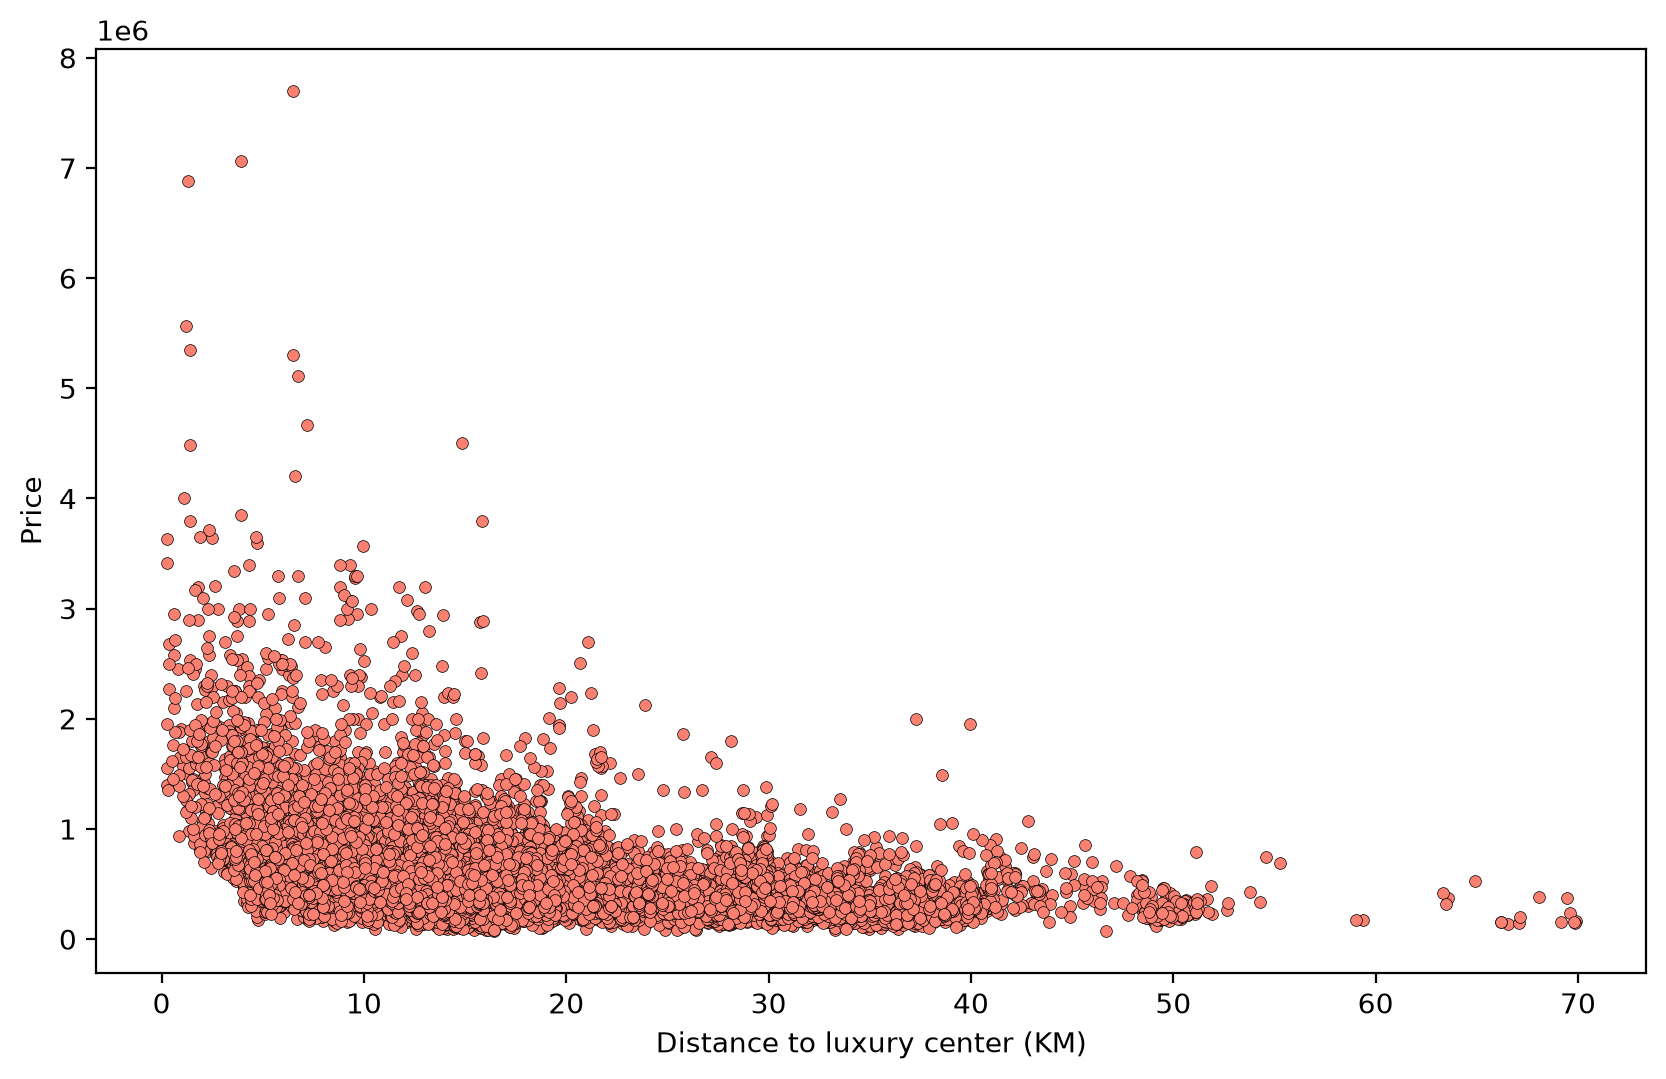

In [44]:
# ploting the price to distance form the expensive mean
fig, ax = plt.subplots(figsize = (10,6))
plt.scatter(y= df.price , x = df['dist_to_luxury_center (KM)'], 
            s = 18,
            edgecolor = 'black',
            linewidths= .25,
            alpha = 1, 
           color = 'salmon')
plt.ylabel('Price')
plt.xlabel('Distance to luxury center (KM)')


In [45]:
# Data is ready to be worked on 
df.to_csv('housing_df_1.csv', index= False)

## Model testing on first dataframe

In [46]:
X = df.drop('price', axis = 1)
y = df['price']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((17289, 19), (17289,), (4323, 19), (4323,))

In [48]:
rf = RandomForestRegressor(random_state= 42)
lr = LinearRegression()

In [49]:
rf.fit(X_train,y_train), lr.fit(X_train,y_train)

(RandomForestRegressor(random_state=42), LinearRegression())

In [50]:
model_1 = rf.score(X_test, y_test)
model_2 = lr.score(X_test, y_test)

**Creating the evaluation function for RandomForestRegression**

In [51]:
# Creating the evaluation function 
from sklearn.metrics import mean_absolute_error, mean_squared_log_error, r2_score

# we will create a function for RMSLE
def rmsle(y_test, y_preds):
    ''' 
    Calculate the root mean squared log error between predictions and true labels.
    '''
    return np.sqrt(mean_squared_log_error(y_test, y_preds))

# Create a function to evaluate model on a few different levels
def show_scores(model):
    test_preds = model.predict(X_test)
    scores = {
        'Test MAE' : mean_absolute_error(y_test, test_preds),
        'Test RMSLE' : rmsle(y_test, test_preds),
        'Test R^2' : r2_score(y_test, test_preds)
    }
    return scores    

In [52]:
show_scores(rf)

{'Test MAE': 71654.97682702159,
 'Test RMSLE': np.float64(0.17927258457743803),
 'Test R^2': 0.8840686003892593}

In [53]:
def show_scores_1(model):
    test_preds = model.predict(X_test)
    scores = {
        'Test MAE' : mean_absolute_error(y_test, test_preds),
        'Test R^2' : r2_score(y_test, test_preds)
    }
    return scores
show_scores_1(lr)

{'Test MAE': 120893.45205869194, 'Test R^2': 0.7314816180836767}

In [54]:
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

### Hyperparameter tuning with RandomizedSearchCV

In [55]:
%%time 
from sklearn.model_selection import RandomizedSearchCV

# Different RandomForestRegressor hyper parameters
rf_grid = {
    'n_estimators' : np.arange(50, 150, 10),
    'max_depth' : [None, 3, 5, 7, 10],
    'min_samples_split' : np.arange(2,20,2),
    'min_samples_leaf' : np.arange(1,20,2),
    'max_features' : [0.5, 0.3,.7, 'sqrt', 'log2']
}

# Instantiate RandomizedSearchCV model 
rs_model = RandomizedSearchCV(RandomForestRegressor(n_jobs= -1,
                                                   random_state= 42),
                                                   param_distributions = rf_grid,
                                                   scoring= 'neg_mean_absolute_error',
                                                   n_iter = 100,
                                                   cv = 10, 
                                                   verbose = True)
rs_model.fit(X_train, y_train)

Fitting 10 folds for each of 100 candidates, totalling 1000 fits
CPU times: user 21min 49s, sys: 18.4 s, total: 22min 8s
Wall time: 2min 36s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 3, ...], 'max_features': [0.5, 0.3, ...], 'min_samples_leaf': array([ 1, 3..., 15, 17, 19]), 'min_samples_split': array([ 2, 4..., 14, 16, 18]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is ma

In [56]:
rs_model.best_params_

{'n_estimators': np.int64(100),
 'min_samples_split': np.int64(18),
 'min_samples_leaf': np.int64(3),
 'max_features': 0.5,
 'max_depth': None}

In [57]:
show_scores(rs_model)

{'Test MAE': 72159.26413110229,
 'Test RMSLE': np.float64(0.178690595527461),
 'Test R^2': 0.8775794391170664}

### Hyperparameter tuning with GridSearchCV

In [58]:
%%time
# Different RandomForestRegressor hyper parameters
gs_grid = {
    'n_estimators' : [100],
    'max_depth' : [None],
    'min_samples_split' : [3,5,6],
    'min_samples_leaf' : [1,2],
    'max_features' : [1.0]
}

from sklearn.model_selection import GridSearchCV
model_gs = GridSearchCV(estimator= RandomForestRegressor(n_jobs= -1),
                         param_grid= gs_grid,
                     cv = 20,
                     verbose= True)

# Fit the model
model_gs.fit(X_train, y_train)

Fitting 20 folds for each of 6 candidates, totalling 120 fits
CPU times: user 19min 43s, sys: 2.49 s, total: 19min 46s
Wall time: 53.5 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...sor(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None], 'max_features': [1.0], 'min_samples_leaf': [1, 2], 'min_samples_split': [3, 5, ...], ...}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",20
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mod

In [59]:
results = pd.DataFrame(model_gs.cv_results_)

columns = (
    ['rank_test_score']
    + [col for col in results.columns if col.startswith('param_')]
    + ['mean_test_score', 'std_test_score']
)

top_20 = (results.sort_values('rank_test_score').head(20)[columns].reset_index(drop = True).rename(columns= lambda col : col.removeprefix('param_')))
display(top_20)


,rank_test_score,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,mean_test_score,std_test_score
0,1,None,1.0,1,3,100,0.883322,0.017110
1,2,None,1.0,2,6,100,0.883255,0.014352
2,3,None,1.0,1,5,100,0.882926,0.016152
3,4,None,1.0,2,5,100,0.882916,0.016316
4,5,None,1.0,2,3,100,0.882822,0.016454
5,6,None,1.0,1,6,100,0.882648,0.015635


In [60]:
model_gs.best_params_

{'max_depth': None,
 'max_features': 1.0,
 'min_samples_leaf': 1,
 'min_samples_split': 3,
 'n_estimators': 100}

In [61]:
show_scores(model_gs)

{'Test MAE': 71593.28925346129,
 'Test RMSLE': np.float64(0.1788150440239226),
 'Test R^2': 0.8832204040518112}

In [62]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age,dist_to_luxury_center (KM)
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,2014,59,12.034162
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,2014,63,12.903333
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2015,82,13.265123
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,2014,49,15.935705
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,2015,28,14.452580
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,2014,5,12.086941
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,2015,1,15.195854
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,2014,5,5.321655
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,2015,11,15.744222


## Working on same df with some changes 

In [63]:
df_2 = df.copy()

**In DataFrame 2 we will be using some more columns to test how much the are helping to improve and also we will be doing log transformation in this**

In [64]:
df_2

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sale_year,age,dist_to_luxury_center (KM)
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,2014,59,12.034162
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,2014,63,12.903333
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2015,82,13.265123
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,2014,49,15.935705
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,2015,28,14.452580
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,2014,5,12.086941
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,2015,1,15.195854
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,2014,5,5.321655
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,2015,11,15.744222


In [65]:
df_2['if_renovated'] = (df.yr_renovated>0).astype(int)
df_2['has_basement'] = (df.sqft_basement>0).astype(int)

In [66]:
df_2

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,yr_built,yr_renovated,zipcode,lat,long,sale_year,age,dist_to_luxury_center (KM),if_renovated,has_basement
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,...,1955,0,98178,47.5112,-122.257,2014,59,12.034162,0,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,...,1951,1991,98125,47.7210,-122.319,2014,63,12.903333,1,1
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,...,1933,0,98028,47.7379,-122.233,2015,82,13.265123,0,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,...,1965,0,98136,47.5208,-122.393,2014,49,15.935705,0,1
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,...,1987,0,98074,47.6168,-122.045,2015,28,14.452580,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,...,2009,0,98103,47.6993,-122.346,2014,5,12.086941,0,0
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,...,2014,0,98146,47.5107,-122.362,2015,1,15.195854,0,0
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,...,2009,0,98144,47.5944,-122.299,2014,5,5.321655,0,0
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,...,2004,0,98027,47.5345,-122.069,2015,11,15.744222,0,0


### Log transformation in df_2

In [67]:
# Creating Size features 
df_2['living_per_bedroom'] = df_2.sqft_living /(df.bedrooms + 1)
df_2['bathroom_per_bedroom'] = df_2.bathrooms / (df.bedrooms + 1)
df_2['living_per_lot'] = df_2.sqft_living / (df.sqft_lot)

In [68]:
df_2

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,lat,long,sale_year,age,dist_to_luxury_center (KM),if_renovated,has_basement,living_per_bedroom,bathroom_per_bedroom,living_per_lot
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,...,47.5112,-122.257,2014,59,12.034162,0,0,295.000000,0.250000,0.208850
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,...,47.7210,-122.319,2014,63,12.903333,1,1,642.500000,0.562500,0.354874
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,...,47.7379,-122.233,2015,82,13.265123,0,0,256.666667,0.333333,0.077000
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,...,47.5208,-122.393,2014,49,15.935705,0,1,392.000000,0.600000,0.392000
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,...,47.6168,-122.045,2015,28,14.452580,0,0,420.000000,0.500000,0.207921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,...,47.6993,-122.346,2014,5,12.086941,0,0,382.500000,0.625000,1.352785
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,...,47.5107,-122.362,2015,1,15.195854,0,0,462.000000,0.500000,0.397385
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,...,47.5944,-122.299,2014,5,5.321655,0,0,340.000000,0.250000,0.755556
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,...,47.5345,-122.069,2015,11,15.744222,0,0,400.000000,0.625000,0.670017


In [69]:
# price , sqft_living, sqft_lot, sqft_above
df_2['price']= np.log1p(df_2['price'])
df_2['sqft_above'] = np.log1p(df_2['sqft_above'])
df_2['sqft_living'] = np.log1p(df_2['sqft_living'])
df_2['sqft_lot'] = np.log1p(df_2['sqft_lot'])

## Model testing for second dataframe

In [70]:
X = df_2.drop('price', axis = 1)
y = df_2['price']

In [71]:
X_train1 , X_test1, y_train1 , y_test1 = train_test_split(X, y, test_size= 0.2)

In [72]:
np.random.seed(42)
lr_2 = LinearRegression()
rf_2 = RandomForestRegressor(random_state= 42)

In [73]:
lr_2.fit(X_train1, y_train1), rf_2.fit(X_train1, y_train1)

(LinearRegression(), RandomForestRegressor(random_state=42))

In [74]:
lr_2.score(X_test1, y_test1), rf_2.score(X_test1, y_test1)

(0.7938180692326064, 0.8818923520678033)

**As we can see there is no big improvement in RandomForestRegressor but in case of LinearRegressor there is a big change of about 6 percent but still that is not sufficient for us to work on LinearRegressor so we will be now work on other models but we will try some other grid search cv for df_2**

In [75]:
%%time
gs_grid_2 = {
    'n_estimators' : [100],
    'max_depth' : [8,9,10],
    'min_samples_split' : [2,3,4],
    'min_samples_leaf' : [1,2,3],
    'max_features' : ['sqrt',None]
}

from sklearn.model_selection import GridSearchCV
model_3 = GridSearchCV(estimator = RandomForestRegressor(n_jobs= -1),
                        param_grid= gs_grid_2,
                        scoring='neg_mean_absolute_error',
                        verbose = True
                       )

model_3.fit(X_train1, y_train1)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
CPU times: user 15min 2s, sys: 5.8 s, total: 15min 8s
Wall time: 59.9 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...sor(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [8, 9, ...], 'max_features': ['sqrt', None], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifi

In [76]:
model_3.best_params_

{'max_depth': 10,
 'max_features': None,
 'min_samples_leaf': 3,
 'min_samples_split': 4,
 'n_estimators': 100}

In [77]:
# Creating the evaluation function 
from sklearn.metrics import mean_absolute_error, mean_squared_log_error, r2_score

# we will create a function for RMSLE
def rmsle(y_test1, y_preds):
    ''' 
    Calculate the root mean squared log error between predictions and true labels.
    '''
    return np.sqrt(mean_squared_log_error(y_test1, y_preds))

# Create a function to evaluate model on a few different levels
def show_scores(model):
    test_preds = model.predict(X_test1)
    scores = {
        'Test MAE' : mean_absolute_error(y_test1, test_preds),
        'Test RMSLE' : rmsle(y_test1, test_preds),
        'Test R^2' : r2_score(y_test1, test_preds)
    }
    return scores 

In [78]:
show_scores(model_3)

{'Test MAE': 0.13267413180097304,
 'Test RMSLE': np.float64(0.013421635019372961),
 'Test R^2': 0.8693578867250967}

In [79]:
y

0        12.309987
1        13.195616
2        12.100718
3        13.311331
4        13.142168
           ...    
21608    12.793862
21609    12.899222
21610    12.904461
21611    12.899222
21612    12.691584
Name: price, Length: 21612, dtype: float64

# Trying other models but we will be working on dataframe 2

## Model 1 : HistGradientBoostingRegressor

In [80]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

In [81]:
df_2

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,lat,long,sale_year,age,dist_to_luxury_center (KM),if_renovated,has_basement,living_per_bedroom,bathroom_per_bedroom,living_per_lot
0,12.309987,3,1.00,7.074117,8.639588,1.0,0,0,3,7,...,47.5112,-122.257,2014,59,12.034162,0,0,295.000000,0.250000,0.208850
1,13.195616,3,2.25,7.852050,8.887791,2.0,0,0,3,7,...,47.7210,-122.319,2014,63,12.903333,1,1,642.500000,0.562500,0.354874
2,12.100718,2,1.00,6.647688,9.210440,1.0,0,0,3,6,...,47.7379,-122.233,2015,82,13.265123,0,0,256.666667,0.333333,0.077000
3,13.311331,4,3.00,7.581210,8.517393,1.0,0,0,5,7,...,47.5208,-122.393,2014,49,15.935705,0,1,392.000000,0.600000,0.392000
4,13.142168,3,2.00,7.427144,8.997271,1.0,0,0,3,8,...,47.6168,-122.045,2015,28,14.452580,0,0,420.000000,0.500000,0.207921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,12.793862,3,2.50,7.333676,7.031741,3.0,0,0,3,8,...,47.6993,-122.346,2014,5,12.086941,0,0,382.500000,0.625000,1.352785
21609,12.899222,4,2.50,7.745436,8.668024,2.0,0,0,3,8,...,47.5107,-122.362,2015,1,15.195854,0,0,462.000000,0.500000,0.397385
21610,12.904461,2,0.75,6.928538,7.208600,2.0,0,0,3,7,...,47.5944,-122.299,2014,5,5.321655,0,0,340.000000,0.250000,0.755556
21611,12.899222,3,2.50,7.378384,7.778630,2.0,0,0,3,8,...,47.5345,-122.069,2015,11,15.744222,0,0,400.000000,0.625000,0.670017


In [82]:
X = df_2.drop('price', axis = 1)
y = df_2['price']

In [83]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size = 0.2)

In [84]:
gbr = GradientBoostingRegressor()
hgbr = HistGradientBoostingRegressor()


In [85]:
gbr.fit(X_train1, y_train1),hgbr.fit(X_train1, y_train1)

(GradientBoostingRegressor(), HistGradientBoostingRegressor())

In [86]:
gbr.score(X_test1,y_test1), hgbr.score(X_test1, y_test1)

(0.881380952758473, 0.8965546832609667)

In [87]:
%%time
# GridSearchCV
estimator = {
    'max_iter' : [100, 150],
    'learning_rate' : [0.05,0.01,0.08],
    'max_leaf_nodes' : [15,31,50],
    'max_depth' : [3,5,8],
    'min_samples_leaf' : [10,20,30],
    'early_stopping' : [True],
    'l2_regularization' : [0.05,0.1,1]
}
from sklearn.model_selection import GridSearchCV
model_4 = GridSearchCV(estimator = HistGradientBoostingRegressor(), 
                     param_grid= estimator,
                     cv= 5,
                     verbose= True,
                     scoring='neg_mean_absolute_error',
                     n_jobs=-1)
model_4.fit(X_train1, y_train1)

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
CPU times: user 32.8 s, sys: 7.15 s, total: 40 s
Wall time: 47.8 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...ingRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'early_stopping': [True], 'l2_regularization': [0.05, 0.1, ...], 'learning_rate': [0.05, 0.01, ...], 'max_depth': [3, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluati

In [88]:
model_4.best_params_

{'early_stopping': True,
 'l2_regularization': 0.1,
 'learning_rate': 0.08,
 'max_depth': 8,
 'max_iter': 150,
 'max_leaf_nodes': 50,
 'min_samples_leaf': 30}

In [89]:
show_scores(model_4)

{'Test MAE': 0.11842052673182656,
 'Test RMSLE': np.float64(0.011937497718579607),
 'Test R^2': 0.8989080829883516}

## Model 2 : XGBoost

In [90]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [91]:
from xgboost import XGBRegressor

In [92]:
model = XGBRegressor(n_estimators = 500, n_jobs= 1)

In [93]:
model.fit(X_train1 , y_train1)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [94]:
model.score(X_test1, y_test1)

0.8880183821753835

In [95]:
%%time
# using estimators 
estimators = {
    'n_estimators' : np.arange(100,300,50),
    'learning_rate' : [0.01,0.05,0.1,0.03],
    'max_depth' : np.arange(2,8,2),
    'min_child_weight' : np.arange(2,6,2),
    'subsample' : np.arange(0.6,1,0.2),
    'colsample_bytree' : np.arange(0.4,1,0.2),
}
model_5 = GridSearchCV(estimator= XGBRegressor(), 
                 param_grid= estimators,
                 n_jobs= -1, 
                 verbose= True
                )
model_5.fit(X_train1, y_train1)

Fitting 5 folds for each of 576 candidates, totalling 2880 fits
CPU times: user 36.9 s, sys: 4.65 s, total: 41.6 s
Wall time: 49.9 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': array([0.4, 0.6, 0.8]), 'learning_rate': [0.01, 0.05, ...], 'max_depth': array([2, 4, 6]), 'min_child_weight': array([2, 4]), ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifi

In [96]:
model_5.best_params_

{'colsample_bytree': np.float64(0.6000000000000001),
 'learning_rate': 0.05,
 'max_depth': np.int64(6),
 'min_child_weight': np.int64(4),
 'n_estimators': np.int64(250),
 'subsample': np.float64(0.8)}

In [97]:
show_scores(model_5)

{'Test MAE': 0.1178300939286436,
 'Test RMSLE': np.float64(0.011848284344452837),
 'Test R^2': 0.9005086801730509}

## Model 3 : LightGBM

In [98]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [99]:
from lightgbm import LGBMRegressor
model = LGBMRegressor()

In [100]:
model.fit(X_train1, y_train1)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003782 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2767
[LightGBM] [Info] Number of data points in the train set: 17289, number of used features: 24
[LightGBM] [Info] Start training from score 13.049417


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [101]:
model.score(X_test1,y_test1)

0.8983574561575306

In [102]:
%%time 
estimators = {
    'n_estimators' : [400],
    'learning_rate' : [0.05],
    'max_depth' : [6,7],
    'num_leaves' : [25, 28],
    'min_child_samples' : [26, 28],
    'colsample_bytree' : [0.6],
    'subsample' : [0.7]
}

model_6 = GridSearchCV(estimator= LGBMRegressor(), 
                 param_grid=estimators,
                 n_jobs= -1 ,
                      verbose= 0)
model_6.fit(X_train1, y_train1)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001310 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2767
[LightGBM] [Info] Number of data points in the train set: 17289, number of used features: 24
[LightGBM] [Info] Start training from score 13.049417
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
CPU times: user 3.86 s, sys: 2.62 s, total: 6.48 s
Wall time: 16.3 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.6], 'learning_rate': [0.05], 'max_depth': [6, 7], 'min_child_samples': [26, 28], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0C

In [103]:
model_6.best_params_

{'colsample_bytree': 0.6,
 'learning_rate': 0.05,
 'max_depth': 7,
 'min_child_samples': 26,
 'n_estimators': 400,
 'num_leaves': 25,
 'subsample': 0.7}

In [104]:
show_scores(model_6)

{'Test MAE': 0.1157684159876091,
 'Test RMSLE': np.float64(0.011682055643075043),
 'Test R^2': 0.9032966986957912}

# Modal Evaluation

In [105]:
# Random forest R2 score
model_1

0.8840686003892593

In [106]:
# Linear Regression
model_2

0.7314816180836767

In [107]:
# Random forest GridSearch df2
show_scores(model_3)

{'Test MAE': 0.11953103839972246,
 'Test RMSLE': np.float64(0.011933060614289177),
 'Test R^2': 0.8989921565684318}

In [108]:
# HistGradientBoostingRegressor
show_scores(model_4)

{'Test MAE': 0.11842052673182656,
 'Test RMSLE': np.float64(0.011937497718579607),
 'Test R^2': 0.8989080829883516}

In [109]:
# XGBoost
show_scores(model_5)

{'Test MAE': 0.1178300939286436,
 'Test RMSLE': np.float64(0.011848284344452837),
 'Test R^2': 0.9005086801730509}

In [110]:
# LightGBM
show_scores(model_6)

{'Test MAE': 0.1157684159876091,
 'Test RMSLE': np.float64(0.011682055643075043),
 'Test R^2': 0.9032966986957912}

## Mapping 

**We will be using LightGBM dataframe 2 for plot as it currently have best results**

In [111]:
model_6.best_estimator_

,num_leaves,25
,max_depth,7
,learning_rate,0.05
,n_estimators,400
,min_child_samples,26
,subsample,0.7
,colsample_bytree,0.6
,boosting_type,'gbdt'
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [112]:
model_6.best_params_

{'colsample_bytree': 0.6,
 'learning_rate': 0.05,
 'max_depth': 7,
 'min_child_samples': 26,
 'n_estimators': 400,
 'num_leaves': 25,
 'subsample': 0.7}

In [113]:
model = LGBMRegressor(colsample_bytree = 0.6,
                        learning_rate = 0.05,
                        max_depth = 6,
                        min_child_samples = 26,
                        n_estimators = 400,
                        num_leaves = 25,
                        subsample = 0.7,
                        verbose=-1
                     )

model.fit(X_train1, y_train1)
y_preds = model.predict(X_test1)

In [114]:
r2_score(y_test1, y_preds)

0.9017651468543955

In [115]:
mean_absolute_error(y_test1, y_preds)

0.1168265253496825

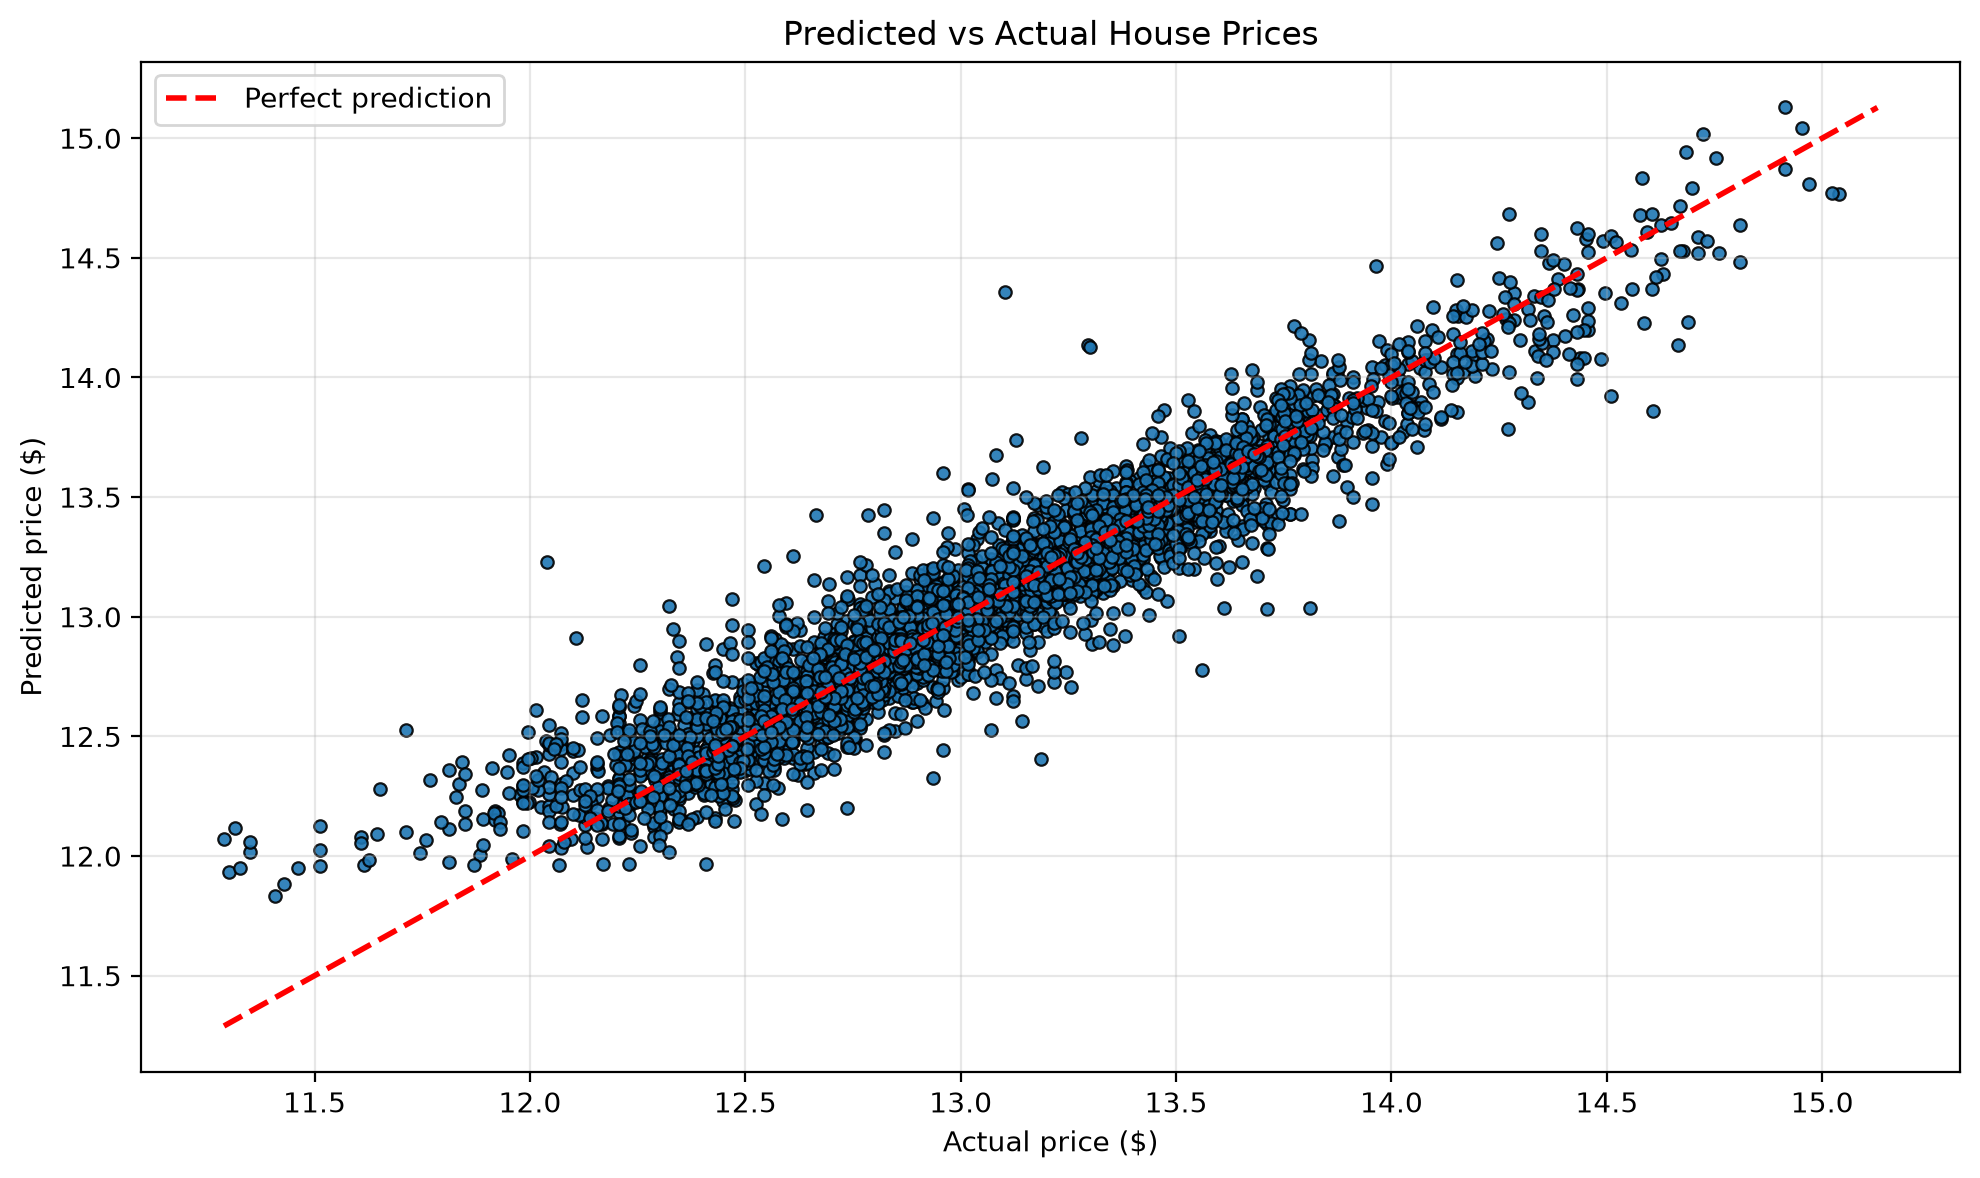

In [116]:
fig, ax = plt.subplots(figsize = (10, 6))
plt.scatter(y_test1, 
            y_preds, 
            alpha = .9, 
            s  = 20, 
            linewidths=.8, 
            edgecolors= 'black')
# prediction line
min_price = min(y_test1.min(), y_preds.min())
max_price = max(y_test1.max(), y_preds.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)
plt.xlabel("Actual price ($)")
plt.ylabel("Predicted price ($)")
plt.title("Predicted vs Actual House Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()